In [3]:
#%%
import math
import numpy as np

import inspect
import importlib

import scipy.interpolate
from scipy import stats
from scipy.stats import norm

import matplotlib
from matplotlib import pyplot as plt
import matplotlib.pyplot as plt
from matplotlib import ticker, cm
from matplotlib import patches as mpatches
from matplotlib.ticker import FuncFormatter
from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.ticker import StrMethodFormatter, NullFormatter
import matplotlib.lines as mlines
from matplotlib import colormaps

import seaborn as sns


plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['font.size'] = 16

import plotly.graph_objects as go
import plotly.express as px
import plotly.io as pio
from plotly.offline import plot
pio.renderers.default = "svg"

import sys
import os
parent_directory = os.path.dirname(os.getcwd())
sys.path.append(parent_directory)
#sys.path.append(os.path.dirname(parent_directory))
#sys.path.append(os.path.dirname(os.path.dirname(parent_directory)))

from IoT_node_models.Energy_model                        import *
from IoT_node_models.Energy_model.Wireless_communication import *
from IoT_node_models.Hardware_Modules                    import *
from IoT_node_models.Analysis                            import *

from fft_architecture_exploration                        import *

path_to_save_svg = "Saved_Data"


rng = np.random.default_rng(42)

bbox_for_text = dict(facecolor='white', edgecolor='none', pad=0, alpha=0.8)

Importing IoT Node models
Importing IoT Node Energy models
Importing IoT Node Energy models
Importing Wireless communication packages
Importing Wireless communication packages
Importing custom modules data
Importing custom modules data
Importing Impact models
Importing Impact models
Importing IoT Node analysis models


In [4]:
fontsize        = 14
fontsize_perc   = 12
fontsize_ytick  = 12
fontsize_legend = 8

matplotlib.rcParams.update({'font.size': fontsize})
matplotlib.rcParams['lines.linewidth'] = 1.5
matplotlib.rcParams['xtick.major.size'] = 5
matplotlib.rcParams['xtick.major.width'] = 1
matplotlib.rcParams['ytick.major.size'] = 5
matplotlib.rcParams['ytick.major.width'] = 1
matplotlib.rc('axes', linewidth=1)


matplotlib.rcParams["font.family"] =  'Avenir LT Pro'
matplotlib.rcParams['figure.facecolor'] = 'white'
matplotlib.rcParams['svg.fonttype'] = 'none'

In [5]:
dictColor = {"DeepBlue"     :"#095256",
             "LightBlue"    :"#01a7c2",
             "UnitedBlue"   :"#6290c8",
             "CerulBlue"    :"#6096ba",
             "Green"        :"#44af69",
             "LightRed"     :"#f8333c",
             "DeepRed"      :"#a22c29",
             "Orange"       :"#fcab10",
             "Sandy"        :"#fc9e4F",
             "Olivine"      :"#9ab87a",
             "CarolinaBlue" :"#009DDC"}
listColor = list(dictColor.values())

In [6]:

import matplotlib.colors as mcolors

# Define base colors for each row
base_colors = {
    'red': '#f8333c',      # LightRed as base
    'blue': "#64ABD4",     # DeepBlue as base  
    'green': '#44af69',    # Green as base
    'orange': '#fcab10',   # Orange as base
}

# Create 10 nuances for each color by varying lightness
color_array_base = np.zeros((4, 10), dtype=object)

for i, (color_name, base_hex) in enumerate(base_colors.items()):
    base_rgb = mcolors.hex2color(base_hex)
    for j in range(10):
        # Create lighter/darker variations by scaling RGB values
        # Use a non-linear scaling for better visual distribution
        

        scaled_rgb = tuple(max(0, min(1, c * (0.6 + 0.6 * ((j) / 3.0)))) for c in base_rgb)
        color_array_base[i, j] = mcolors.rgb2hex(scaled_rgb)

color_array = np.zeros((4, 11), dtype=object)
color_array[:, 1:] = color_array_base
color_array[: , 0] = '#000000'


# Rename rows for clarity
color_names = ['red', 'blue', 'green', 'orange', 'purple']

In [7]:



importlib.reload(sys.modules['fft_architecture_exploration'])
from fft_architecture_exploration import * 

In [8]:
analysis_Mem_type  = np.array([1]) # 0: 1xSP SRAM,   1: 2xSP SRAM, 2: 2xHalf-size SP SRAM,  3: 1xDP SRAM
analysis_nMem_type = len(analysis_Mem_type)

baseline_area    = pipe_theor_Area[0,analysis_Mem_type]
add_baseline_area = False

baseline_techNode= 65 #10
baseline_energy  = pipe_theor_Energy [0,analysis_Mem_type]
baseline_latency = pipe_theor_Latency[0,analysis_Mem_type]
baseline_power   = baseline_energy / baseline_latency

area_overlap = 0#0.095

beta = 1.0

In [9]:
analysis_Mem_type  = np.array([1]) # 0: 1xSP SRAM,   1: 2xSP SRAM, 2: 2xHalf-size SP SRAM,  3: 1xDP SRAM
analysis_nMem_type = len(analysis_Mem_type)



#baseline_area    = [10/((90/65)**2)]
baseline_area    = 0.493           
add_baseline_area = True


baseline_techNode= 65 #10
baseline_energy  = nFFT* 5.7e-9     
baseline_latency = nFFT* 79         * 10
baseline_power   = baseline_energy / baseline_latency

area_overlap = 0#0.095

beta = 1

In [10]:
alpha_s_low  = -2
alpha_s_high = 5
alpha_n = (alpha_s_high - alpha_s_low)*40
alpha_studied = np.logspace(alpha_s_low, alpha_s_high, alpha_n+1,endpoint=True)

In [11]:
arch_Dim = max(len(paraLevel),len(pipeLevel),len(paraPipeLevel))

In [12]:
cm0_energy_ratio = 1/2
cm0_area_ratio   = 2
cm0_speedup_ratio= 2.5

cm0_Energy  = baseline_energy*cm0_energy_ratio
cm0_Area    = baseline_area  *cm0_area_ratio
cm0_Latency = baseline_latency*cm0_speedup_ratio
cm0_area_delta = cm0_Area - baseline_area 

In [13]:
# ----------------------------------------------------------------------
#           RATIO
# ----------------------------------------------------------------------


para_theor_Speedup        = baseline_latency        / para_theor_Latency                                
para_theor_Power          = para_theor_Energy       / para_theor_Latency
   
pipePara_theor_Speedup    = baseline_latency            / pipePara_theor_Latency                                
pipePara_theor_Power      = pipePara_theor_Energy       / pipePara_theor_Latency 

pipe_theor_Speedup        = baseline_latency        / pipe_theor_Latency                                
pipe_theor_Power          = pipe_theor_Energy       / pipe_theor_Latency

# ----------------------------------------------------------------------

theor_Area             = np.array([pipe_theor_Area         ,  para_theor_Area     ,  pipePara_theor_Area      ]) - area_overlap
theor_Area_Mem         = np.array([pipe_theor_Area_Mem     ,  para_theor_Area_Mem ,  pipePara_theor_Area_Mem  ]) - area_overlap
theor_Area_BF          = np.array([pipe_theor_Area_BF      ,  para_theor_Area_BF  ,  pipePara_theor_Area_BF   ]) - area_overlap

theor_Energy           = np.array([pipe_theor_Energy       ,  para_theor_Energy       ,  pipePara_theor_Energy      ])
theor_Energy_Mem       = np.array([pipe_theor_Energy_Mem   ,  para_theor_Energy_Mem   ,  pipePara_theor_Energy_Mem  ])
theor_Energy_BF        = np.array([pipe_theor_Energy_BF    ,  para_theor_Energy_BF    ,  pipePara_theor_Energy_BF   ])


theor_Latency          = np.array([pipe_theor_Latency      ,  para_theor_Latency  ,  pipePara_theor_Latency])
theor_Speedup          = np.array([pipe_theor_Speedup      ,  para_theor_Speedup  ,  pipePara_theor_Speedup])                              
theor_Power            = np.array([pipe_theor_Power        ,  para_theor_Power    ,  pipePara_theor_Power]) 

# ----------------------------------------------------------------------

para_theor_area_delta    = (para_theor_Area[:,:,np.newaxis]+baseline_area*add_baseline_area - area_overlap)    - baseline_area
para_theor_area_ratio    = (para_theor_Area[:,:,np.newaxis]+baseline_area*add_baseline_area - area_overlap)    / baseline_area
para_theor_power_ratio   = para_theor_Power   / baseline_power
para_theor_energy_ratio  = para_theor_Energy  / baseline_energy
para_theor_latency_ratio = para_theor_Latency / baseline_latency
para_theor_speedup_ratio = 1/(para_theor_latency_ratio)


# ----------------------------------------------------------------------
pipe_theor_area_delta    = (pipe_theor_Area[:,:,np.newaxis]+baseline_area*add_baseline_area - area_overlap)    - baseline_area
pipe_theor_area_ratio    = (pipe_theor_Area[:,:,np.newaxis]+baseline_area*add_baseline_area - area_overlap)    / baseline_area
pipe_theor_power_ratio   = pipe_theor_Power   / baseline_power
pipe_theor_energy_ratio  = pipe_theor_Energy  / baseline_energy
pipe_theor_latency_ratio = pipe_theor_Latency / baseline_latency
pipe_theor_speedup_ratio = 1/(pipe_theor_latency_ratio)


# ----------------------------------------------------------------------
pipePara_theor_area_delta    = (pipePara_theor_Area[:,:,np.newaxis]+baseline_area*add_baseline_area - area_overlap)    - baseline_area
pipePara_theor_area_ratio    = (pipePara_theor_Area[:,:,np.newaxis]+baseline_area*add_baseline_area - area_overlap)    / baseline_area
pipePara_theor_power_ratio   = pipePara_theor_Power   / baseline_power
pipePara_theor_energy_ratio  = pipePara_theor_Energy  / baseline_energy
pipePara_theor_latency_ratio = pipePara_theor_Latency / baseline_latency
pipePara_theor_speedup_ratio = 1/(pipePara_theor_latency_ratio)

# ----------------------------------------------------------------------


theor_area_ratio        = np.array([pipe_theor_area_ratio       , para_theor_area_ratio    , pipePara_theor_area_ratio])  
theor_area_delta        = np.array([pipe_theor_area_delta       , para_theor_area_delta    , pipePara_theor_area_delta])  
theor_power_ratio       = np.array([pipe_theor_power_ratio      , para_theor_power_ratio   , pipePara_theor_power_ratio])
theor_energy_ratio      = np.array([pipe_theor_energy_ratio     , para_theor_energy_ratio  , pipePara_theor_energy_ratio])
theor_latency_ratio     = np.array([pipe_theor_latency_ratio    , para_theor_latency_ratio , pipePara_theor_latency_ratio])                              
theor_speedup_ratio     = np.array([pipe_theor_speedup_ratio    , para_theor_speedup_ratio , pipePara_theor_speedup_ratio]) 

In [14]:
for k in range(3):
    for i in range(arch_Dim):
        for d, j in enumerate(analysis_Mem_type):
            print(f"THEOR {k}{j},{i}:  area={theor_Area[k,i,j]:.4f} : Mem={theor_Area_Mem[k,i,j]*100/theor_Area[k,i,j]:.2f}%,  BF={theor_Area_BF[k,i,j]*100/theor_Area[k,i,j]:.2f}% \t Energy={theor_Energy[k,i,j]:.2e} : Mem={theor_Energy_Mem[k,i,j]*100/theor_Energy[k,i,j]:.2f}%,  BF={theor_Energy_BF[k,i,j]*100/theor_Energy[k,i,j]:.2f}%")


THEOR 01,0:  area=0.1949 : Mem=96.96%,  BF=3.04% 	 Energy=2.80e-06 : Mem=85.93%,  BF=14.07%
THEOR 01,1:  area=0.2008 : Mem=94.11%,  BF=5.89% 	 Energy=1.59e-06 : Mem=75.34%,  BF=24.66%
THEOR 01,2:  area=0.2068 : Mem=91.41%,  BF=8.59% 	 Energy=1.19e-06 : Mem=67.07%,  BF=32.93%
THEOR 01,3:  area=0.2127 : Mem=88.87%,  BF=11.13% 	 Energy=9.94e-07 : Mem=60.43%,  BF=39.57%
THEOR 01,4:  area=nan : Mem=nan%,  BF=nan% 	 Energy=nan : Mem=nan%,  BF=nan%
THEOR 11,0:  area=0.1949 : Mem=96.96%,  BF=3.04% 	 Energy=2.80e-06 : Mem=85.93%,  BF=14.07%
THEOR 11,1:  area=0.2370 : Mem=95.01%,  BF=4.99% 	 Energy=2.16e-06 : Mem=81.77%,  BF=18.23%
THEOR 11,2:  area=0.2853 : Mem=91.70%,  BF=8.30% 	 Energy=1.75e-06 : Mem=77.50%,  BF=22.50%
THEOR 11,3:  area=0.3705 : Mem=87.22%,  BF=12.78% 	 Energy=1.58e-06 : Mem=75.08%,  BF=24.92%
THEOR 11,4:  area=0.5651 : Mem=83.24%,  BF=16.76% 	 Energy=1.47e-06 : Mem=73.25%,  BF=26.75%
THEOR 21,0:  area=0.1949 : Mem=96.96%,  BF=3.04% 	 Energy=2.80e-06 : Mem=85.93%,  BF=14.07%


In [15]:
#----------------------------------------------------------------------------------

our_Area           = np.array([0.119    , 0.123    , 0.129    , 0.141    ] ) + 0.095
our_NFFT           = np.array([4096     , 4096     , 4096     , 4096     ] )                 
our_Latency_pFFT   = np.array([98423    , 49250    , 32883    , 24723    ] )     /2          
our_Energy_pFFT    = np.array([3388.9   , 1922.4   , 1434.1   , 1197.6    ] ) *1e-9 

our_Latency        = our_Latency_pFFT   
our_Energy         = our_Energy_pFFT       
our_Speedup        = baseline_latency / our_Latency                                
our_Power          = our_Energy       / our_Latency  

our_area_ratio    = (our_Area[:,np.newaxis]+baseline_area*add_baseline_area)    / baseline_area
our_area_delta    = (our_Area[:,np.newaxis]+baseline_area*add_baseline_area)    - baseline_area
our_power_ratio   = our_Power   / baseline_power
our_energy_ratio  = our_Energy  / baseline_energy
our_latency_ratio = our_Latency / baseline_latency
our_speedup_ratio = 1/(our_latency_ratio)

#----------------------------------------------------------------------------------
soA_name          =           [ "Pereira 22" , "Berta. 21 ", "Gonz. 24",  "Yang 21", "Mahdavi 19", "Shih 18", "Shih 18", "Tian 19"  , "Paul 25"  , "Zhang 25" ,"Maistriaux 26" ,  "Liu 18"   ]         #"Deng 23"
soA_type          =           [ "Memory-b"   , "Memory-b"  , "Memory-b",  "Pipel." , "Pipel."    , "Pipel." , "Pipel." , "Memory-b" , "Memory-b" , "Memory-b" ,"Memory-b"      ,  "Memory-b" ]         #"Pipel." 
soA_show          =           [   False      ,  False      , False     ,  False    , False       ,   False  , False    ,  True      ,  False     ,  True      , True           ,    True     ]         #"Pipel." 
soA_marker        =           [    "s"       ,    "s"      ,   "s"     ,    "s"    ,   "s"       ,   "s"    ,   "<"    ,    ">"     ,    ">"     ,    ">"     ,   ">"          ,     "*"     ]         #"Pipel." 
soA_techNode      =           [    65        , 22          , 22        ,  65       , 28          , 40       , 40       ,65          , 65         , 40         ,65              ,     65      ]         #40
soa_Area_FFT       = np.array([    0.185     , 0.185       , 1.08      ,  1.83     , 0.57        , 1.09     , 1.25     ,0.84        , 3.8        , 1.11       ,0.1445          ,    1.67     ] )       #0.48                        
soa_NFFT           = np.array([    256       , 1024        , 1024      ,  2048     , 2048        , 2048     , 4096     ,4096        , 4096       , 4096       ,4096            ,    4096     ] )       #1024                       
soa_Latency_pFFT   = np.array([    1025      , 3005        , 1320      ,  2048     , 1200        , 2048     , 4096     ,5120        , 605        , 2259       ,24723           ,    768      ] )       #245                         
soa_Energy_pFFT    = np.array([    187.23    , 1054.78     , 297.92    ,  260.31   , 600.82      , 541.60   , 1658.43  ,599.04      , 495.67     , 1221.50    ,1230            ,   240.98    ] ) *1e-9 #22.94      

soa_Area           = scale_area    (area= soa_Area_FFT,        nfft_ref = 4096, nfft = soa_NFFT, acc_type =soA_type)    
soa_Latency        = scale_latency (latency= soa_Latency_pFFT, nfft_ref = 4096, nfft = soa_NFFT, acc_type =soA_type)                      
soa_Energy         = soa_Energy_pFFT  * (4096*12/(soa_NFFT*np.log2(soa_NFFT)))     
 
soa_Speedup        = baseline_latency / soa_Latency                               
soa_Power          = soa_Energy       / soa_Latency  

soa_area_ratio    = (soa_Area[:,np.newaxis]+baseline_area*add_baseline_area)    / baseline_area
soa_area_delta    = (soa_Area[:,np.newaxis]+baseline_area*add_baseline_area)    - baseline_area
soa_power_ratio   = soa_Power   / baseline_power
soa_energy_ratio  = soa_Energy  / baseline_energy
soa_latency_ratio = soa_Latency / baseline_latency
soa_speedup_ratio = 1/(soa_latency_ratio)



In [16]:
use_delta = False

if use_delta:
    def asi_function(alpha = 0.5, base_area  = 1, delta_area=1, base_energy = 1 ,new_energy=1,speedup=1):
        return (-(delta_area*base_energy/(base_area*new_energy*alpha)) + (base_energy/new_energy))/speedup

    def wfi_function(alpha = 0.5, base_area  = 1, delta_area=1, base_energy = 1 ,new_energy=1):
        return (-(delta_area*base_energy/(base_area*new_energy*alpha)) + (base_energy/new_energy))

else:
    def asi_function(alpha = 0.5, area_ratio  = 1, energy_ratio = 1 ,speedup=1):
        return (1+alpha-area_ratio)/(alpha*energy_ratio*speedup)

    def wfi_function(alpha = 0.5, area_ratio  = 1, energy_ratio = 1):
        return (1+alpha-area_ratio)/(alpha*energy_ratio)

In [17]:


# ----------------------------------------------------------------------
# 2a. DERIVE RATIOS 
# ----------------------------------------------------------------------

theor_asi_res     = np.zeros((len(alpha_studied),3,arch_Dim,analysis_nMem_type))
theor_ncf_res     = np.zeros((len(alpha_studied),3,arch_Dim,analysis_nMem_type,2))
for k in range(3):
    for i in range(arch_Dim):
        for d, j in enumerate(analysis_Mem_type):
            if use_delta:
                theor_asi_res[:,k,i,d]  = asi_function(alpha = alpha_studied, base_area  = baseline_area, delta_area=theor_area_delta[k,i,j]+baseline_area*add_baseline_area, base_energy = baseline_energy ,new_energy=theor_Energy[k,i,j],speedup=theor_speedup_ratio[k,i,j])                      
                theor_ncf_res[:,k,i,d,0]= (theor_area_delta[k,i,j])/baseline_area +  (alpha_studied * (                           theor_Energy[k,i,j] - baseline_energy) )/baseline_energy
                theor_ncf_res[:,k,i,d,1]= (theor_area_delta[k,i,j])/baseline_area +  (alpha_studied * (theor_speedup_ratio[k,i,j]*theor_Energy[k,i,j] - baseline_energy) )/baseline_energy
            else:  
                theor_asi_res[:,k,i,d]  = asi_function (alpha=alpha_studied, area_ratio=theor_area_ratio[k,i,j], energy_ratio=theor_energy_ratio[k,i,j],speedup=theor_speedup_ratio[k,i,j])        
                theor_ncf_res[:,k,i,d,0]= (theor_area_ratio[k,i,j]) +  (alpha_studied * (                           theor_energy_ratio[k,i,j]))
                theor_ncf_res[:,k,i,d,1]= (theor_area_ratio[k,i,j]) +  (alpha_studied * (theor_speedup_ratio[k,i,j]*theor_energy_ratio[k,i,j]))
    
            print(f"THEOR {k}{j},{i}:  area={theor_Area[k,i,j]:.4f},  power_ratio={theor_power_ratio[k,i,j]:.2f}, energy_ratio={theor_energy_ratio[k,i,j]:.2f}, speedup={theor_speedup_ratio[k,i,j]:.2e}, ncf={theor_ncf_res[0,k,i,d,0]:.2e}")


theor_ncf_test     = np.zeros((len(alpha_studied),3,arch_Dim,analysis_nMem_type))
for k in range(3):
    for i in range(arch_Dim):
        for d, j in enumerate(analysis_Mem_type):
            if use_delta:
                theor_ncf_test[:,k,i,d]= wfi_function(alpha = alpha_studied, base_area  = baseline_area, delta_area=theor_area_delta[k,i,j], base_energy = baseline_energy ,new_energy=theor_Energy[k,i,j])
            else:
                theor_ncf_test[:,k,i,d]= wfi_function (alpha=alpha_studied, area_ratio=theor_area_ratio[k,i,j], energy_ratio=theor_energy_ratio[k,i,j])   


# ----------------------------------------------------------------------

our_asi_res    = np.zeros((len(alpha_studied),len(our_area_ratio)))
our_ncf_res    = np.zeros((len(alpha_studied),len(our_area_ratio),2))
for i in range(our_area_ratio.shape[0]):

    if use_delta:
        our_asi_res[:,i]  = asi_function(alpha = alpha_studied, base_area  = baseline_area, delta_area=our_area_delta[i]+baseline_area*add_baseline_area, base_energy = baseline_energy ,new_energy=our_Energy[i],speedup=our_speedup_ratio[i])                      
        our_ncf_res[:,i,0]= (our_area_delta[i])/baseline_area +  (alpha_studied * (                     our_Energy[i] - baseline_energy) )/baseline_energy
        our_ncf_res[:,i,1]= (our_area_delta[i])/baseline_area +  (alpha_studied * (our_speedup_ratio[i]*our_Energy[i] - baseline_energy) )/baseline_energy
    else:   
        our_asi_res[:,i]    = asi_function (alpha=alpha_studied, area_ratio=our_area_ratio[i], energy_ratio=our_energy_ratio[i],speedup=our_speedup_ratio[i])  
        our_ncf_res[:,i,0]  = (our_area_ratio[i]) +  (alpha_studied * (                     our_energy_ratio[i]))
        our_ncf_res[:,i,1]  = (our_area_ratio[i]) +  (alpha_studied * (our_speedup_ratio[i]*our_energy_ratio[i]))

our_ncf_test =   np.zeros((len(alpha_studied),len(our_area_ratio)))
for i in range(our_area_ratio.shape[0]):
    if use_delta:
        our_ncf_test[:,i]= wfi_function(alpha = alpha_studied, base_area  = baseline_area, delta_area=our_area_delta[i], base_energy = baseline_energy ,new_energy=our_Energy[i])
    else:
        our_ncf_test[:,i]= wfi_function (alpha=alpha_studied, area_ratio=our_area_ratio[i], energy_ratio=our_energy_ratio[i])   


# ----------------------------------------------------------------------

soa_asi_res    = np.zeros((len(alpha_studied),len(soa_area_ratio)))
soa_ncf_res    = np.zeros((len(alpha_studied),len(soa_area_ratio),2))
for i in range(soa_area_ratio.shape[0]):

    if use_delta:
        soa_asi_res[:,i]  = asi_function(alpha = alpha_studied, base_area  = baseline_area, delta_area=soa_area_delta[i]+baseline_area*add_baseline_area, base_energy = baseline_energy ,new_energy=soa_Energy[i],speedup=soa_speedup_ratio[i])                      
        soa_ncf_res[:,i,0]= (soa_area_delta[i])/baseline_area +  (alpha_studied * (                     soa_Energy[i] - baseline_energy) )/baseline_energy
        soa_ncf_res[:,i,1]= (soa_area_delta[i])/baseline_area +  (alpha_studied * (soa_speedup_ratio[i]*soa_Energy[i] - baseline_energy) )/baseline_energy
    else:   
        soa_asi_res[:,i]    = asi_function (alpha=alpha_studied, area_ratio=soa_area_ratio[i], energy_ratio=soa_energy_ratio[i],speedup=soa_speedup_ratio[i])  
        soa_ncf_res[:,i,0]  = (soa_area_ratio[i]) +  (alpha_studied * (                     soa_energy_ratio[i]))
        soa_ncf_res[:,i,1]  = (soa_area_ratio[i]) +  (alpha_studied * (soa_speedup_ratio[i]*soa_energy_ratio[i]))

soa_ncf_test =   np.zeros((len(alpha_studied),len(soa_area_ratio)))
for i in range(soa_area_ratio.shape[0]):
    if use_delta:
        soa_ncf_test[:,i]= wfi_function(alpha = alpha_studied, base_area  = baseline_area, delta_area=soa_area_delta[i], base_energy = baseline_energy ,new_energy=soa_Energy[i])
    else:
        soa_ncf_test[:,i]= wfi_function (alpha=alpha_studied, area_ratio=soa_area_ratio[i] , energy_ratio=soa_energy_ratio[i])   

# ----------------------------------------------------------------------

cm0_asi_res    = np.zeros((len(alpha_studied)))
cm0_ncf_res    = np.zeros((len(alpha_studied),2))
cm0_ncf_test =   np.zeros((len(alpha_studied)))

if use_delta:
    cm0_asi_res[:]  = asi_function(alpha = alpha_studied, base_area  = baseline_area, delta_area=cm0_area_delta+baseline_area*add_baseline_area, base_energy = baseline_energy ,new_energy=cm0_Energy,speedup=cm0_speedup_ratio)                      
    cm0_ncf_res[:,0]= (cm0_area_delta)/baseline_area +  (alpha_studied * (                     cm0_Energy - baseline_energy) )/baseline_energy
    cm0_ncf_res[:,1]= (cm0_area_delta)/baseline_area +  (alpha_studied * (cm0_speedup_ratio   *cm0_Energy - baseline_energy) )/baseline_energy
else:   
    cm0_asi_res[:]    = asi_function (alpha=alpha_studied, area_ratio=cm0_area_ratio, energy_ratio=cm0_energy_ratio,speedup=cm0_speedup_ratio)  
    cm0_ncf_res[:,0]  = (cm0_area_ratio) +  (alpha_studied * (                     cm0_energy_ratio))
    cm0_ncf_res[:,1]  = (cm0_area_ratio) +  (alpha_studied * (cm0_speedup_ratio   *cm0_energy_ratio))


if use_delta:
    cm0_ncf_test[:]= wfi_function(alpha = alpha_studied, base_area  = baseline_area, delta_area=cm0_area_delta, base_energy = baseline_energy ,new_energy=cm0_Energy)
else:
    cm0_ncf_test[:]= wfi_function (alpha=alpha_studied, area_ratio=cm0_area_ratio , energy_ratio=cm0_energy_ratio)   



THEOR 01,0:  area=0.1949,  power_ratio=7.88, energy_ratio=0.12, speedup=6.58e+01, ncf=1.40e+00
THEOR 01,1:  area=0.2008,  power_ratio=8.99, energy_ratio=0.07, speedup=1.32e+02, ncf=1.41e+00
THEOR 01,2:  area=0.2068,  power_ratio=10.10, energy_ratio=0.05, speedup=1.98e+02, ncf=1.42e+00
THEOR 01,3:  area=0.2127,  power_ratio=11.21, energy_ratio=0.04, speedup=2.63e+02, ncf=1.43e+00
THEOR 01,4:  area=nan,  power_ratio=nan, energy_ratio=nan, speedup=nan, ncf=nan
THEOR 11,0:  area=0.1949,  power_ratio=7.88, energy_ratio=0.12, speedup=6.58e+01, ncf=1.40e+00
THEOR 11,1:  area=0.2370,  power_ratio=12.16, energy_ratio=0.09, speedup=1.32e+02, ncf=1.48e+00
THEOR 11,2:  area=0.2853,  power_ratio=19.71, energy_ratio=0.07, speedup=2.63e+02, ncf=1.58e+00
THEOR 11,3:  area=0.3705,  power_ratio=35.60, energy_ratio=0.07, speedup=5.27e+02, ncf=1.75e+00
THEOR 11,4:  area=0.5651,  power_ratio=66.32, energy_ratio=0.06, speedup=1.05e+03, ncf=2.15e+00
THEOR 21,0:  area=0.1949,  power_ratio=7.88, energy_ratio=0

In [18]:
min_energy = np.nanmin(theor_Energy)
min_energy = np.nanmin(soa_Energy)
print(min_energy)
for k in range(3):
    for i in range(arch_Dim):
        for d, j in enumerate(analysis_Mem_type):
            print(f"THEOR {k}{j},{i}: energy ratio compared to BiC={theor_Energy[k,i,j]/min_energy:.2f},        energy={theor_Energy[k,i,j]:.2e}")


2.4098000000000003e-07
THEOR 01,0: energy ratio compared to BiC=11.60,        energy=2.80e-06
THEOR 01,1: energy ratio compared to BiC=6.62,        energy=1.59e-06
THEOR 01,2: energy ratio compared to BiC=4.95,        energy=1.19e-06
THEOR 01,3: energy ratio compared to BiC=4.12,        energy=9.94e-07
THEOR 01,4: energy ratio compared to BiC=nan,        energy=nan
THEOR 11,0: energy ratio compared to BiC=11.60,        energy=2.80e-06
THEOR 11,1: energy ratio compared to BiC=8.95,        energy=2.16e-06
THEOR 11,2: energy ratio compared to BiC=7.25,        energy=1.75e-06
THEOR 11,3: energy ratio compared to BiC=6.55,        energy=1.58e-06
THEOR 11,4: energy ratio compared to BiC=6.10,        energy=1.47e-06
THEOR 21,0: energy ratio compared to BiC=11.60,        energy=2.80e-06
THEOR 21,1: energy ratio compared to BiC=8.95,        energy=2.16e-06
THEOR 21,2: energy ratio compared to BiC=4.44,        energy=1.07e-06
THEOR 21,3: energy ratio compared to BiC=3.27,        energy=7.88e-07


In [19]:
alpha_to_study_array = np.array([0.05, 500,5000])

Text(0, 0.5, 'EAP')

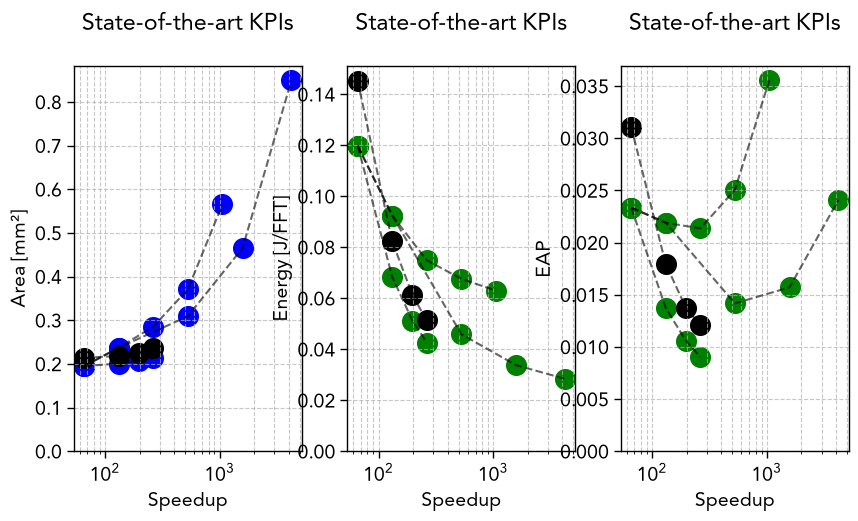

In [20]:
alpha_not_fft_size   = 0.3
plot_scaled_fft_size = 1

markersize = 200

soa_patch      = mlines.Line2D([], [], color='gray', marker="s", markersize=8, linewidth=0, label='State-of-the-Art')
soa_pt_patch   = mlines.Line2D([], [], color='gray', marker="<", markersize=8, linewidth=0, label='Liu 2018')
model_patch    = mlines.Line2D([], [], color='gray', marker="o", markersize=8, linewidth=0, label='FFT HW Acc. Model')
our_patch      = mlines.Line2D([], [], color='gray', marker="o", markersize=8, linewidth=0, label='Our DWIFgn')

nPlot = 3
fig, ax = plt.subplots(1,nPlot, figsize=(10, 5), squeeze=False)


#sc = ax[0,0].scatter(   1,1, s=markersize ,  alpha=1, marker = 'o', color="black") 

for d, i in enumerate(analysis_Mem_type):
    for j in range(3):
        ax[0,0].plot(            theor_speedup_ratio[j,:,i], theor_Area[j,:,i], color = 'black', alpha=0.6, linestyle ='--')
        sc = ax[0,0].scatter(    theor_speedup_ratio[j,:,i], theor_Area[j,:,i], s=markersize ,  alpha=1, marker = 'o', color = 'blue')

        
        ax[0,1].plot(           theor_speedup_ratio[j,:,i],  theor_energy_ratio[j,:,i], color = 'black', alpha=0.6, linestyle ='--')
        sc = ax[0,1].scatter(   theor_speedup_ratio[j,:,i],  theor_energy_ratio[j,:,i], s=markersize ,  alpha=1, marker = 'o', color = 'green')

        
        ax[0,2].plot(           theor_speedup_ratio[j,:,i],  theor_Area[j,:,i]*theor_energy_ratio[j,:,i], color = 'black', alpha=0.6, linestyle ='--')
        sc = ax[0,2].scatter(   theor_speedup_ratio[j,:,i],  theor_Area[j,:,i]*theor_energy_ratio[j,:,i], s=markersize ,  alpha=1, marker = 'o', color = 'green')
        
ax[0,0].plot(           our_speedup_ratio,  our_Area, color = 'black', alpha=0.6, linestyle ='--')
sc = ax[0,0].scatter(   our_speedup_ratio,  our_Area, s=markersize ,  alpha=1, marker = 'o', color = 'black')
ax[0,1].plot(           our_speedup_ratio,  our_energy_ratio, color = 'black', alpha=0.6, linestyle ='--')
sc = ax[0,1].scatter(   our_speedup_ratio,  our_energy_ratio, s=markersize ,  alpha=1, marker = 'o', color = 'black')
ax[0,2].plot(           our_speedup_ratio,  our_Area*our_energy_ratio, color = 'black', alpha=0.6, linestyle ='--')
sc = ax[0,2].scatter(   our_speedup_ratio,  our_Area*our_energy_ratio, s=markersize ,  alpha=1, marker = 'o', color = 'black')



#ax.legend()
#ax.legend(handles=[soa_patch, soa_pt_patch, model_patch, our_patch],fontsize = 13)

for i in range(nPlot):
    ax[0,i].set_ylim([0, None])
    ax[0,i].set_yscale('linear')

    #ax[0,i].set_xlim([0, None])
    ax[0,i].set_xscale('log')

    ax[0,i].grid(True, which='both', linestyle='--', alpha=0.7)
    ax[0,i].set_xlabel('Speedup')
    ax[0,i].set_title('State-of-the-art KPIs\n')

ax[0,0].set_ylabel('Area [mm²]')
ax[0,1].set_ylabel('Energy [J/FFT]')
ax[0,2].set_ylabel('EAP')

In [21]:
alpha_not_fft_size   = 0.3
plot_scaled_fft_size = 0
plot_our             = 0  

this_plot = 0

if this_plot:



    markersize = 200

    soa_patch      = mlines.Line2D([], [], color='gray', marker="s", markersize=8, linewidth=0, label='State-of-the-Art')
    soa_pt_patch   = mlines.Line2D([], [], color='gray', marker="<", markersize=8, linewidth=0, label='Liu 2018')
    model_patch    = mlines.Line2D([], [], color='gray', marker="o", markersize=8, linewidth=0, label='FFT HW Acc. Model')
    our_patch      = mlines.Line2D([], [], color='gray', marker="o", markersize=8, linewidth=0, label='Our DWIFgn')

    fig, ax = plt.subplots(1,1, figsize=(6, 5))

    ######################################################################################################################

    ax.axline(xy1=[np.nanmin(theor_Speedup[:,:,analysis_Mem_type]), np.nanmin(theor_Area[:,:,analysis_Mem_type])],slope = 1, color="black", alpha=0.5)

    if plot_our:
        ax.plot(our_Speedup    , our_Area  , color = "black")
        sc = ax.scatter(our_Speedup   , our_Area   , s=markersize , c= our_Energy   ,  cmap='RdYlGn_r', vmin =np.min(soa_Energy)   ,vmax = np.nanmax(pipe_theor_Energy),  marker = 'o', edgecolors="black",label="Our Approach"    ,alpha=1              )  #s=our_Power*4e12   

    for i in range(len(soA_techNode)):
        if soA_show[i] :
            sc = ax.scatter(soa_Speedup[i]  , soa_Area[i]   , s=markersize , c= soa_Energy[i]   ,  cmap='RdYlGn_r', vmin =np.nanmin(soa_Energy)   ,vmax = np.nanmax(pipe_theor_Energy),  marker = soA_marker[i], edgecolors="black",label="State-of-the-Art",alpha = 1)  #s=soa_Power*4e12   

    for d, i in enumerate(analysis_Mem_type):
        for j in range(3):
            ax.plot(theor_Speedup[j,:arch_Dim_array[j],i], theor_Area[j,:arch_Dim_array[j],i], color = 'black', alpha=0.6, linestyle ='--')
            sc = ax.scatter(    theor_Speedup[j,:arch_Dim_array[j],i],     theor_Area[j,:arch_Dim_array[j],i], s=markersize , c=     theor_Energy[j,:arch_Dim_array[j],i],  cmap='RdYlGn_r', vmin =np.nanmin(soa_Energy),vmax = np.nanmax(theor_Energy), alpha=1, marker = 'o', edgecolors="black") #  s=    theor_Power[j,:,i]*4e12

    fig.colorbar(sc, ax=ax, label='Energy per point [J]', location='right')

    #ax.legend()
    #ax.legend(handles=[soa_patch, soa_pt_patch, model_patch, our_patch],fontsize = 13)

    ax.set_yscale('log')
    ax.set_xscale('log')
    ax.grid(True, which='both', linestyle='--', alpha=0.7)
    ax.set_ylabel('Area [mm²]')
    ax.set_xlabel('Speedup')
    ax.set_title('State-of-the-art KPIs\n')

    ######################################################################################################################
    fig, ax = plt.subplots(1,1, figsize=(6, 5))

    normArea = colors.LogNorm(vmin=np.nanmin(theor_Area), vmax=np.nanmax(soa_Area))

    ax.axline(xy1=[np.nanmin(theor_Speedup[:,:,analysis_Mem_type]), np.nanmin(theor_power_ratio[:,:,analysis_Mem_type])],slope = 1, color="black", alpha=0.5)

    if plot_our:
        ax.plot(our_Speedup    , our_power_ratio  , color = "black")        
        sc = ax.scatter(our_Speedup   , our_power_ratio   , s=markersize , c= our_Area   ,  norm=normArea, cmap='Oranges', marker = 'o', edgecolors="black",label="Our Approach"                            ) # s=our_Area*2e3   

    for i in range(len(soA_techNode)):
        if soA_show[i] :
            sc = ax.scatter(soa_Speedup[i]   , soa_power_ratio [i]  , s=markersize , c= soa_Area[i]   ,  norm=normArea, cmap='Oranges', marker = soA_marker[i], edgecolors="black",label="State-of-the-Art", alpha = 1) # s=soa_Area*2e3   

    for i in analysis_Mem_type:
        for j in range(3):
            ax.plot(theor_Speedup[j,:arch_Dim_array[j],i], theor_power_ratio[j,:arch_Dim_array[j],i], color = 'black', alpha=0.6, linestyle ='--')
            sc = ax.scatter(    theor_Speedup[j,:arch_Dim_array[j],i],     theor_power_ratio[j,:arch_Dim_array[j],i], s=markersize , c=     theor_Area[j,:arch_Dim_array[j],i],  norm=normArea, cmap='Oranges', alpha=1, marker = 'o', edgecolors="black") # s=    theor_Area[j,:,i]*2e3

    fig.colorbar(sc, ax=ax, label='Area [mm2]', location='right')

    #ax.legend()
    #ax.legend(handles=[soa_patch, soa_pt_patch, model_patch, our_patch],fontsize = 13)

    ax.set_yscale('log')
    ax.set_xscale('log')
    ax.grid(True, which='both', linestyle='--', alpha=0.7)
    ax.set_ylabel('Power')
    ax.set_xlabel('Speedup')
    ax.set_title('State-of-the-art KPIs\n')


    ######################################################################################################################
    fig, ax = plt.subplots(1,1, figsize=(6, 5))

    ax.axline(xy1=[np.nanmin(theor_Speedup[:,:,analysis_Mem_type]), np.nanmin(1/theor_energy_ratio[:,:,analysis_Mem_type])],slope = 1, color="black", alpha=0.5)

    if plot_our:
        ax.plot(our_Speedup    , 1/our_energy_ratio  , color = "black")
        sc = ax.scatter(our_Speedup   , 1/our_energy_ratio   , s = markersize , c= our_Area    ,norm=normArea,  cmap='Oranges',  marker = 'o', edgecolors="black", label="Our Approach"                            ) #s=our_Area*2e3   

    for i in range(len(soA_techNode)):
        if soA_show[i] :
            sc = ax.scatter(soa_Speedup[i]   , 1/soa_energy_ratio[i]   , s = markersize , c= soa_Area[i]    ,norm=normArea,  cmap='Oranges',  marker = soA_marker[i], edgecolors="black", label="State-of-the-Art", alpha = 1) #s=soa_Area*2e3   

    for i in analysis_Mem_type:
        for j in range(3):
            ax.plot(theor_Speedup[j,:arch_Dim_array[j],i], 1/theor_energy_ratio[j,:arch_Dim_array[j],i], color = 'black', alpha=0.6, linestyle ='--')
            sc = ax.scatter(    theor_Speedup[j,:arch_Dim_array[j],i],     1/theor_energy_ratio[j,:arch_Dim_array[j],i], s = markersize ,norm=normArea, c=     theor_Area[j,:arch_Dim_array[j],i],  cmap='Oranges',   alpha=1, marker = 'o', edgecolors="black") # s=    theor_Area[j,:,i]*2e3
            
    fig.colorbar(sc, ax=ax, label='Area [mm2]', location='right')


    #ax.legend()
    #ax.legend(handles=[soa_patch, soa_pt_patch, model_patch, our_patch],fontsize = 13, loc='right', bbox_to_anchor=(2,0.5) )
    ax.set_yscale('log')
    ax.set_xscale('log')
    ax.grid(True, which='both', linestyle='--', alpha=0.7)
    ax.set_ylabel('Energy efficiency')
    ax.set_xlabel('Speedup')
    ax.set_title('State-of-the-art KPIs\n')



    ######################################################################################################################
    fig, ax = plt.subplots(1,1, figsize=(6, 5))

    ax.axline(xy1=[np.nanmin( 1/theor_energy_ratio[:,:,analysis_Mem_type]), np.nanmin( theor_Area[:,:,analysis_Mem_type])],slope = 1, color="black", alpha=0.5)

    if plot_our:
        ax.plot( 1/our_energy_ratio,our_Area  , color = "black")
        sc = ax.scatter(1/our_energy_ratio,our_Area   , s = markersize , c= our_Area    ,norm=normArea,  cmap='Oranges',  marker = 'o', edgecolors="black", label="Our Approach"                            ) #s=our_Area*2e3   

    for i in range(len(soA_techNode)):
        if soA_show[i] :
            sc = ax.scatter( 1/soa_energy_ratio[i] ,soa_Area[i]    , s = markersize , c= soa_Area[i]    ,norm=normArea,  cmap='Oranges',  marker = soA_marker[i], edgecolors="black", label="State-of-the-Art", alpha = 1) #s=soa_Area*2e3   

    for i in analysis_Mem_type:
        for j in range(3):
            ax.plot(1/theor_energy_ratio[j,:arch_Dim_array[j],i],theor_Area[j,:arch_Dim_array[j],i], color = 'black', alpha=0.6, linestyle ='--')
            sc = ax.scatter( 1/theor_energy_ratio[j,:arch_Dim_array[j],i], theor_Area[j,:arch_Dim_array[j],i], s = markersize ,norm=normArea, c=     theor_Area[j,:arch_Dim_array[j],i],  cmap='Oranges',   alpha=1, marker = 'o', edgecolors="black") # s=    theor_Area[j,:,i]*2e3
            

    ax.set_yscale('log')
    ax.set_xscale('log')
    ax.grid(True, which='both', linestyle='--', alpha=0.7)
    ax.set_ylabel('Area [mm²]')
    ax.set_xlabel('Energy efficiency')
    ax.set_title('State-of-the-art KPIs\n')

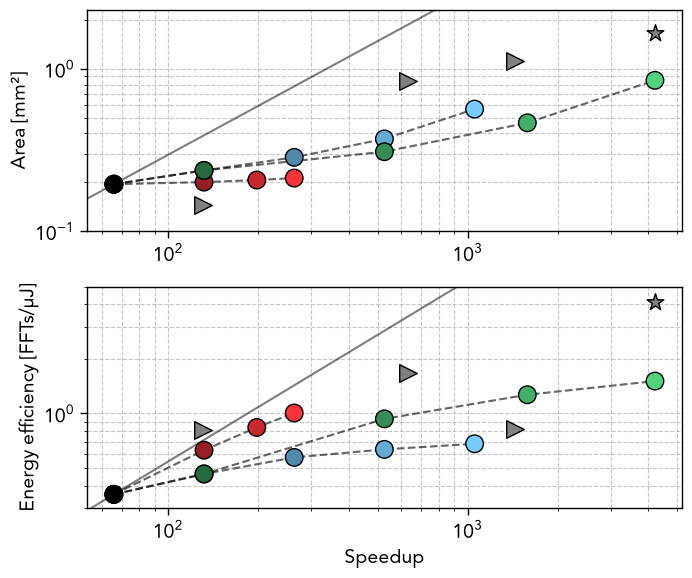

In [22]:
alpha_not_fft_size   = 0.3
plot_scaled_fft_size = 0
plot_our             = 0  

markersize = 160

soa_patch      = mlines.Line2D([], [], color='gray', marker="s", markersize=8, linewidth=0, label='State-of-the-Art')
soa_pt_patch   = mlines.Line2D([], [], color='gray', marker="<", markersize=8, linewidth=0, label='Liu 2018')
model_patch    = mlines.Line2D([], [], color='gray', marker="o", markersize=8, linewidth=0, label='FFT HW Acc. Model')
our_patch      = mlines.Line2D([], [], color='gray', marker="o", markersize=8, linewidth=0, label='Our DWIFgn')

fig, ax = plt.subplots(2,1, figsize=(7.14, 6))

######################################################################################################################

ax[0].axline(xy1=[np.nanmin(theor_Speedup[:,:,analysis_Mem_type]), np.nanmin(theor_Area[:,:,analysis_Mem_type])],slope = 1, color="black", alpha=0.5)

if plot_our:
    ax[0].plot(our_Speedup    , our_Area  , color = "black")
    sc = ax[0].scatter(our_Speedup   , our_Area   , s=markersize ,  marker = 'o', color="gray", edgecolors="black",label="Our Approach"    ,alpha=1              )  #s=our_Power*4e12   

for i in range(len(soA_techNode)):
    if soA_show[i] :
        sc = ax[0].scatter(soa_Speedup[i]  , soa_Area[i]   , s=markersize ,  marker = soA_marker[i], color="gray", edgecolors="black",label="State-of-the-Art",alpha = 1, zorder=5)  #s=soa_Power*4e12   

for d, i in enumerate(analysis_Mem_type):
    for j in range(3):
        ax[0].plot(theor_Speedup[j,:arch_Dim_array[j],i], theor_Area[j,:arch_Dim_array[j],i], color = 'black', alpha=0.6, linestyle ='--')
        sc = ax[0].scatter(    theor_Speedup[j,:arch_Dim_array[j],i],     theor_Area[j,:arch_Dim_array[j],i], s=markersize , c=color_array[j,:arch_Dim_array[j]],  alpha=1, marker = 'o', edgecolors="black", zorder=5) #  s=    theor_Power[j,:,i]*4e12

#ax.legend()
#ax.legend(handles=[soa_patch, soa_pt_patch, model_patch, our_patch],fontsize = 13)

ax[0].set_yscale('log')
ax[0].set_xscale('log')
ax[0].grid(True, which='both', linestyle='--', alpha=0.7)
ax[0].set_ylabel('Area [mm²]')
ax[0].yaxis.set_minor_formatter(NullFormatter())
ax[0].set_ylim([0.1,2.3])


######################################################################################################################

ax[1].axline(xy1=[np.nanmin(theor_Speedup[:,:,analysis_Mem_type]), np.nanmin(1e-6/theor_Energy[:,:,analysis_Mem_type])],slope = 1, color="black", alpha=0.5)

if plot_our:
    ax[1].plot(our_Speedup    , 1e-6/our_Energy  , color = "black")
    sc = ax[1].scatter(our_Speedup   , 1e-6/our_Energy   , s = markersize ,  marker = 'o',color='gray', edgecolors="black", label="Our Approach"                            ) #s=our_Area*2e3   

for i in range(len(soA_techNode)):
    if soA_show[i] :
        sc = ax[1].scatter(soa_Speedup[i]   , 1e-6/soa_Energy[i]   , s = markersize , marker = soA_marker[i],color='gray', edgecolors="black", label="State-of-the-Art", alpha = 1, zorder=5) #s=soa_Area*2e3   

for i in analysis_Mem_type:
    for j in range(3):
        ax[1].plot(theor_Speedup[j,:arch_Dim_array[j],i], 1e-6/theor_Energy[j,:arch_Dim_array[j],i], color = 'black', alpha=0.6, linestyle ='--')
        sc = ax[1].scatter(    theor_Speedup[j,:arch_Dim_array[j],i],     1e-6/theor_Energy[j,:arch_Dim_array[j],i], c=color_array[j,:arch_Dim_array[j]], s = markersize ,   alpha=1, marker = 'o', edgecolors="black", zorder=5) # s=    theor_Area[j,:,i]*2e3
        
#ax.legend()
#ax.legend(handles=[soa_patch, soa_pt_patch, model_patch, our_patch],fontsize = 13, loc='right', bbox_to_anchor=(2,0.5) )
ax[1].set_yscale('log')
ax[1].set_xscale('log')
ax[1].grid(True, which='both', linestyle='--', alpha=0.7)
ax[1].set_ylabel('Energy efficiency [FFTs/µJ]')
ax[1].set_xlabel('Speedup')
ax[1].set_ylim([0.3,5])
ax[1].yaxis.set_minor_formatter(NullFormatter())
fig.tight_layout()

plt.savefig("SoA.svg", bbox_inches="tight")


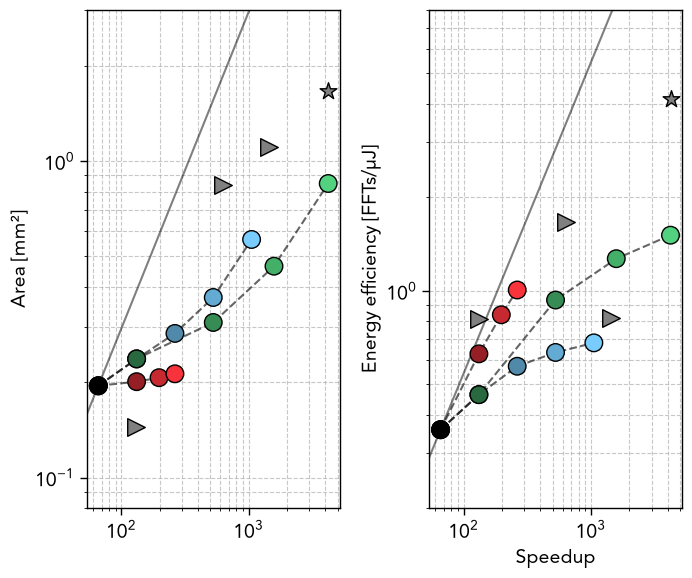

In [23]:
alpha_not_fft_size   = 0.3
plot_scaled_fft_size = 0
plot_our             = 0  

markersize = 160

soa_patch      = mlines.Line2D([], [], color='gray', marker="s", markersize=8, linewidth=0, label='State-of-the-Art')
soa_pt_patch   = mlines.Line2D([], [], color='gray', marker="<", markersize=8, linewidth=0, label='Liu 2018')
model_patch    = mlines.Line2D([], [], color='gray', marker="o", markersize=8, linewidth=0, label='FFT HW Acc. Model')
our_patch      = mlines.Line2D([], [], color='gray', marker="o", markersize=8, linewidth=0, label='Our DWIFgn')

fig, ax = plt.subplots(1,2, figsize=(7.14, 6))

######################################################################################################################

ax[0].axline(xy1=[np.nanmin(theor_Speedup[:,:,analysis_Mem_type]), np.nanmin(theor_Area[:,:,analysis_Mem_type])],slope = 1, color="black", alpha=0.5)

if plot_our:
    ax[0].plot(our_Speedup    , our_Area  , color = "black")
    sc = ax[0].scatter(our_Speedup   , our_Area   , s=markersize ,  marker = 'o', color="gray", edgecolors="black",label="Our Approach"    ,alpha=1              )  #s=our_Power*4e12   

for i in range(len(soA_techNode)):
    if soA_show[i] :
        sc = ax[0].scatter(soa_Speedup[i]  , soa_Area[i]   , s=markersize ,  marker = soA_marker[i], color="gray", edgecolors="black",label="State-of-the-Art",alpha = 1, zorder=5)  #s=soa_Power*4e12   

for d, i in enumerate(analysis_Mem_type):
    for j in range(3):
        ax[0].plot(theor_Speedup[j,:arch_Dim_array[j],i], theor_Area[j,:arch_Dim_array[j],i], color = 'black', alpha=0.6, linestyle ='--')
        sc = ax[0].scatter(    theor_Speedup[j,:arch_Dim_array[j],i],     theor_Area[j,:arch_Dim_array[j],i], s=markersize , c=color_array[j,:arch_Dim_array[j]],  alpha=1, marker = 'o', edgecolors="black", zorder=5) #  s=    theor_Power[j,:,i]*4e12

#ax.legend()
#ax.legend(handles=[soa_patch, soa_pt_patch, model_patch, our_patch],fontsize = 13)

ax[0].set_yscale('log')
ax[0].set_xscale('log')
ax[0].grid(True, which='both', linestyle='--', alpha=0.7)
ax[0].set_ylabel('Area [mm²]')
ax[0].set_ylim([0.08,3])


######################################################################################################################

ax[1].axline(xy1=[np.nanmin(theor_Speedup[:,:,analysis_Mem_type]), np.nanmin(1e-6/theor_Energy[:,:,analysis_Mem_type])],slope = 1, color="black", alpha=0.5)

if plot_our:
    ax[1].plot(our_Speedup    , 1e-6/our_Energy  , color = "black")
    sc = ax[1].scatter(our_Speedup   , 1e-6/our_Energy   , s = markersize ,  marker = 'o',color='gray', edgecolors="black", label="Our Approach"                            ) #s=our_Area*2e3   

for i in range(len(soA_techNode)):
    if soA_show[i] :
        sc = ax[1].scatter(soa_Speedup[i]   , 1e-6/soa_Energy[i]   , s = markersize , marker = soA_marker[i],color='gray', edgecolors="black", label="State-of-the-Art", alpha = 1, zorder=5) #s=soa_Area*2e3   

for i in analysis_Mem_type:
    for j in range(3):
        ax[1].plot(theor_Speedup[j,:arch_Dim_array[j],i], 1e-6/theor_Energy[j,:arch_Dim_array[j],i], color = 'black', alpha=0.6, linestyle ='--')
        sc = ax[1].scatter(    theor_Speedup[j,:arch_Dim_array[j],i],     1e-6/theor_Energy[j,:arch_Dim_array[j],i], c=color_array[j,:arch_Dim_array[j]], s = markersize ,   alpha=1, marker = 'o', edgecolors="black", zorder=5) # s=    theor_Area[j,:,i]*2e3
        
#ax.legend()
#ax.legend(handles=[soa_patch, soa_pt_patch, model_patch, our_patch],fontsize = 13, loc='right', bbox_to_anchor=(2,0.5) )
ax[1].set_yscale('log')
ax[1].set_xscale('log')
ax[1].grid(True, which='both', linestyle='--', alpha=0.7)
ax[1].set_ylabel('Energy efficiency [FFTs/µJ]')
ax[1].set_xlabel('Speedup')
ax[1].set_ylim([0.2,8])
ax[1].yaxis.set_minor_formatter(NullFormatter())
fig.tight_layout()

plt.savefig("SoA.svg", bbox_inches="tight")


(0.2, 5)

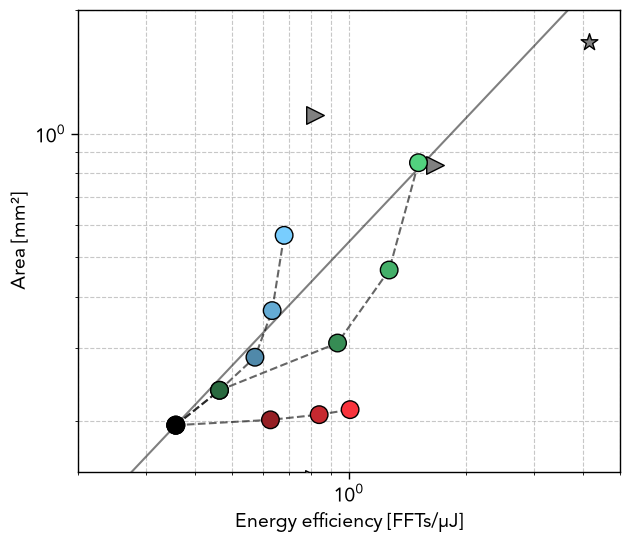

In [24]:
alpha_not_fft_size   = 0.3
plot_scaled_fft_size = 0
plot_our             = 0  

markersize = 160

soa_patch      = mlines.Line2D([], [], color='gray', marker="s", markersize=8, linewidth=0, label='State-of-the-Art')
soa_pt_patch   = mlines.Line2D([], [], color='gray', marker="<", markersize=8, linewidth=0, label='Liu 2018')
model_patch    = mlines.Line2D([], [], color='gray', marker="o", markersize=8, linewidth=0, label='FFT HW Acc. Model')
our_patch      = mlines.Line2D([], [], color='gray', marker="o", markersize=8, linewidth=0, label='Our DWIFgn')

fig, ax = plt.subplots(1,1, figsize=(7, 6))

######################################################################################################################

ax.axline(xy1=[np.nanmin(1e-6/theor_Energy[:,:,analysis_Mem_type]), np.nanmin(theor_Area[:,:,analysis_Mem_type])],slope = 1, color="black", alpha=0.5)

if plot_our:
    ax.plot(1e-6/our_Energy    , our_Area  , color = "black")
    sc = ax.scatter(1e-6/our_Energy   , our_Area   , s=markersize ,  marker = 'o', color="gray", edgecolors="black",label="Our Approach"    ,alpha=1              )  #s=our_Power*4e12   

for i in range(len(soA_techNode)):
    if soA_show[i] :
        sc = ax.scatter(1e-6/soa_Energy[i]  , soa_Area[i]   , s=markersize ,  marker = soA_marker[i], color="gray", edgecolors="black",label="State-of-the-Art",alpha = 1, zorder=5)  #s=soa_Power*4e12   

for d, i in enumerate(analysis_Mem_type):
    for j in range(3):
        ax.plot(1e-6/theor_Energy[j,:arch_Dim_array[j],i], theor_Area[j,:arch_Dim_array[j],i], color = 'black', alpha=0.6, linestyle ='--')
        sc = ax.scatter(    1e-6/theor_Energy[j,:arch_Dim_array[j],i],     theor_Area[j,:arch_Dim_array[j],i], s=markersize , c=color_array[j,:arch_Dim_array[j]],  alpha=1, marker = 'o', edgecolors="black", zorder=5) #  s=    theor_Power[j,:,i]*4e12

#ax.legend()
#ax.legend(handles=[soa_patch, soa_pt_patch, model_patch, our_patch],fontsize = 13)

ax.set_yscale('log')
ax.set_xscale('log')
ax.grid(True, which='both', linestyle='--', alpha=0.7)
ax.set_ylabel('Area [mm²]')
ax.set_xlabel('Energy efficiency [FFTs/µJ]')

ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_formatter(NullFormatter())

ax.set_ylim([0.15,2])
ax.set_xlim([0.2,5])



[[22530  6149  2050   775]
 [47448 12306  4107  1547]]
[[24576.  6144.  2048.   768.]
 [49152. 12288.  4096.  1536.]]


Text(0.5, 1.0, 'State-of-the-art KPIs\n')

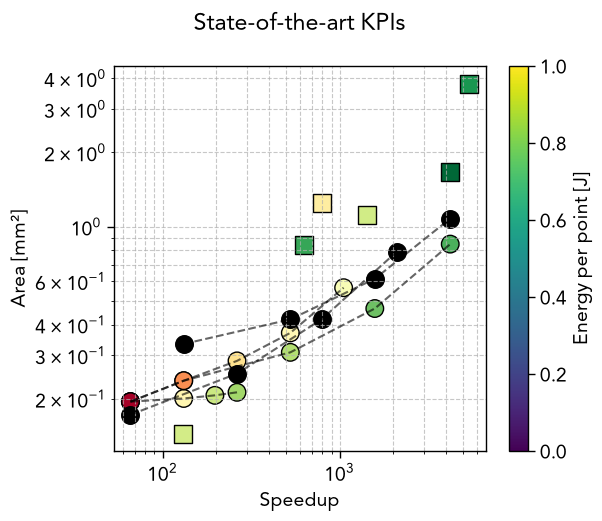

In [25]:
HLS_Radix       = np.array([ [ 2       ,4       ,8       ,16  ],[    2       ,4       ,8       ,16    ]])
HLS_Port        = np.array([ [ 2       ,2       ,2       ,2   ],[    1       ,1       ,1       ,1     ]])
HLS_latency_µs  = np.array([ [ 13.3    ,3.63    ,2.44    ,1.02],[    28.48   ,8.79    ,6.04    ,2.21  ]]) *2
HLS_Area        = np.array([ [ 0.062   ,0.078   ,0.114   ,0.2 ],[    0.032   ,0.047   ,0.078   ,0.147 ]]) *(65**2)/(28**2)
HLS_Freq_MHz    = np.array([ [ 847     ,847     ,420     ,380 ],[    833     ,700     ,340     ,350   ]])

HLS_cycle = np.round(HLS_latency_µs*HLS_Freq_MHz).astype(int)
print(HLS_cycle)
HLS_cycle = 4096*np.ceil(np.log2(4096)/np.log2(HLS_Radix))/HLS_Radix /(HLS_Port/2)
print(HLS_cycle)

fig, ax = plt.subplots(1,1, figsize=(6, 5))


for i in range(len(soA_techNode)):
    if soa_NFFT[i] == nFFT:
        sc = ax.scatter(soa_Speedup[i]  , soa_Area[i]   , s=markersize , c= soa_Energy[i]   ,  cmap='RdYlGn_r', vmin =np.nanmin(soa_Energy)   ,vmax = np.nanmax(pipe_theor_Energy),  marker = 's', edgecolors="black",label="State-of-the-Art",alpha = 1)  #s=soa_Power*4e12   
    elif (plot_scaled_fft_size==1): 
        sc = ax.scatter(soa_Speedup[i]  , soa_Area[i]   , s=markersize , c= soa_Energy[i]   ,  cmap='RdYlGn_r', vmin =np.nanmin(soa_Energy)   ,vmax = np.nanmax(pipe_theor_Energy),  marker = 's', edgecolors="black",label="State-of-the-Art",alpha = alpha_not_fft_size)  #s=soa_Power*4e12   


for d, i in enumerate(analysis_Mem_type):
    for j in range(3):
        ax.plot(theor_Speedup[j,:,i], theor_Area[j,:,i], color = 'black', alpha=0.6, linestyle ='--')
        sc = ax.scatter(    theor_Speedup[j,:,i],     theor_Area[j,:,i], s=markersize , c=     theor_Energy[j,:,i],  cmap='RdYlGn_r', vmin =np.nanmin(soa_Energy),vmax = np.nanmax(theor_Energy), alpha=1, marker = 'o', edgecolors="black") #  s=    theor_Power[j,:,i]*4e12

for i in range(2):
    ax.plot(baseline_latency/HLS_cycle[i,:], HLS_Area[i,:], color = 'black', alpha=0.6, linestyle ='--')
    sc = ax.scatter( baseline_latency/HLS_cycle[i,:],  HLS_Area[i,:], s=markersize ,  alpha=1, marker = 'o', edgecolors="black", color="black") #  s=    theor_Power[j,:,i]*4e12

fig.colorbar(sc, ax=ax, label='Energy per point [J]', location='right')

ax.set_yscale('log')
ax.set_xscale('log')
ax.grid(True, which='both', linestyle='--', alpha=0.7)
ax.set_ylabel('Area [mm²]')
ax.set_xlabel('Speedup')
ax.set_title('State-of-the-art KPIs\n')

In [26]:
def F_p_kWh_to_p_J (F_p_kWh):

    return F_p_kWh / 3600000 

def F_p_mAh_to_p_kWh (F_p_mAh, V):

    return F_p_mAh * 1e6 / (V)

def F_p_mAh_to_p_J (F_p_mAh, V):

    return F_p_mAh / (3600/1000 * V)

#-------------- Grid ----------------------
grid_data = {
"World"                         : 0.458,  
"China"                         : 0.525, 
"US"                            : 0.384, 
"France"                        : 0.041, 
"Taiwan"                        : 0.633, 
"ASEAN"                         : 0.56501,  
"Africa"                        : 0.52988,  
"Asia"                          : 0.5444,   
"EU"                            : 0.2099,   
"Europe"                        : 0.28268,  
"G20"                           : 0.45329,  
"G7"                            : 0.34242,  
"Latin America and Caribbean"   : 0.24697,  
"Middle East"                   : 0.63461,  
"North America"                 : 0.35995,  
"OECD"                          : 0.33593,   
"Oceania"                       : 0.46987
}


F_p_kWh_grid = grid_data["World"]
#-------------- Non-Rechargeable Batt. ----------------------
V_alkaline_AA = 1.5
F_p_mAh_nrBatt_Hamade    = (0.107)/2800


In [28]:

F_p_J_grid = F_p_kWh_to_p_J(grid_data["World"]) 
F_p_J_batt = F_p_mAh_to_p_J(F_p_mAh_nrBatt_Hamade,V_alkaline_AA)
print(F_p_J_batt)
F_p_J_EH   = 439.04251924782244 / (365*24*60*60*10)


F_p_mm2 = 0.97/100


cases_array= np.array([
    # Name,               Area          , Emb      Carbon In  Lifetime      fs
    [ " Biomed - batt  " ,baseline_area , F_p_mm2, F_p_J_batt,    10  ,    3.6e2  ],
    #[ " Audio - grid   " ,baseline_area , F_p_mm2, F_p_J_grid,    10  ,    1.6e4  ],
    [ " Audio - EH     " ,baseline_area , F_p_mm2, F_p_J_EH  ,    10  ,    1.6e4  ],
    #[ " Audio - batt   " ,baseline_area , F_p_mm2, F_p_J_batt,    10  ,    1.6e4  ],
    [ " Intensive-grid " ,baseline_area , F_p_mm2, F_p_J_grid,    10  ,      4e6  ],
])
# Embodied

array_name     = cases_array[:,0]
array_area     = cases_array[:,1].astype(float)
array_F_p_mm2  = cases_array[:,2].astype(float)
array_F_p_J    = cases_array[:,3].astype(float)
array_lifetime = cases_array[:,4].astype(float)
array_fs       = cases_array[:,5].astype(float)

base_emb = array_F_p_mm2*array_area 
print(base_emb)
base_op =  array_fs*array_F_p_J*(365*24*60*60*array_lifetime)*baseline_energy/nFFT 
array_alpha = base_op/base_emb

for i, name in enumerate(array_name):
    print("Use case : %s, \t Alpha = %.4f"%(name,array_alpha[i]))

7.076719576719577e-06
[0.0047821 0.0047821 0.0047821]
Use case :  Biomed - batt  , 	 Alpha = 0.9576
Use case :  Audio - EH     , 	 Alpha = 8.3730
Use case :  Intensive-grid , 	 Alpha = 191.2871


C:\Users\maistriauxp\AppData\Local\Temp\ipykernel_32400\4233852213.py:133: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[-1,0].legend()


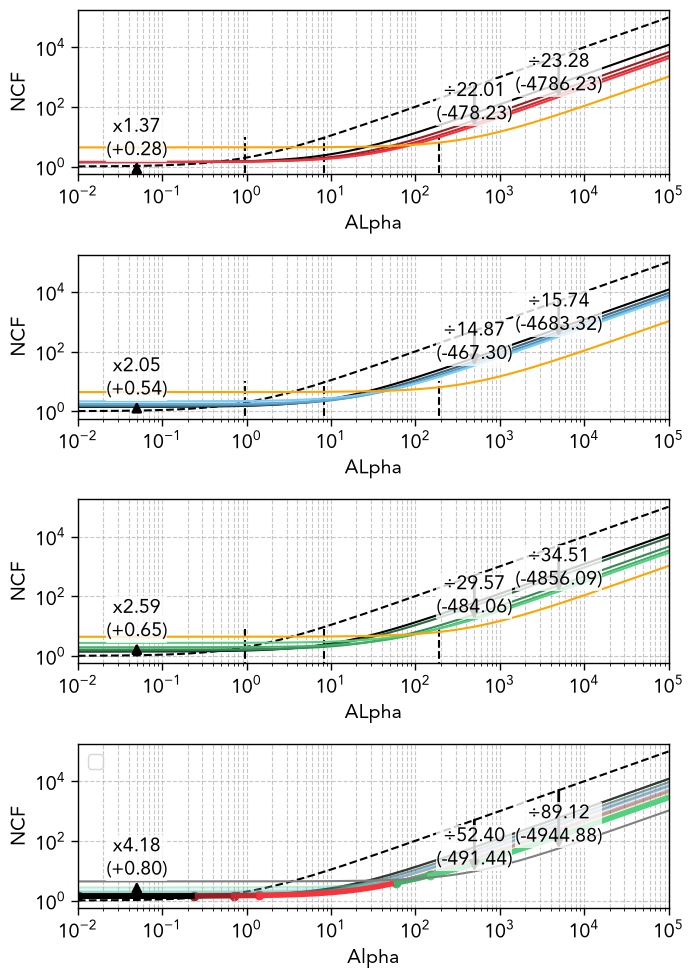

In [59]:
plot_theor = 1
plot_soa = 1
plot_our = 0
plot_soa_only_last_one =1
highlight_best = 1


# Plot the operation footprint vs FFT throughput
fig, ax = plt.subplots(4,1,figsize=(7.16, 10), sharey='row', squeeze=False)
####################################################################################################################################

for k in range(3):
    ax[k,0].set_xlabel('ALpha')
    ax[k,0].set_xlabel('ALpha')
    ax[k,0].grid(True, which='both', linestyle='--', alpha=0.7)
    ax[k,0].grid(True, which='both', linestyle='--', alpha=0.7)

    # Add our accelerator
    
    for i, alp in enumerate(array_alpha):
        p = ax[k,0].vlines(alp,ymin=0, ymax= 10,   color = 'black' , linestyle ='--')

    p = ax[k,0].plot(alpha_studied,  1+alpha_studied,   color = 'black' , linestyle ='--', label = "Baseline system")

    for i in range(0,arch_Dim):
        for d, j in enumerate(analysis_Mem_type):
            p = ax[k,0].plot(alpha_studied,   theor_ncf_res[:,k,i,d,0],   color = color_array[k,i] , linestyle ='-', label = "Acc. level %i"%(i+1))

    for a, alpha_val in enumerate(alpha_to_study_array):
        for d, j in enumerate(analysis_Mem_type):
            index = np.argmin(np.abs(alpha_studied-alpha_val))
            ratio = (1+alpha_val)/theor_ncf_res[index,k,arch_Dim_array[k]-1,d,0]
            ax[k,0].annotate('', xy=(alpha_val, theor_ncf_res[index,k,arch_Dim_array[k]-1,d,0]), xytext=(alpha_val, 1+alpha_val),arrowprops=dict(arrowstyle='-|>', color='black', lw=2, shrinkA = 0, shrinkB = 0))
            if ratio>1:
                ax[k,0].text(alpha_val,  theor_ncf_res[index,k,arch_Dim_array[k]-1,d,0] , "÷%.2f\n(-%.2f)"%(ratio,(1-(1/ratio))*(1+alpha_val)), ha='center', va='bottom',  color="black",bbox=bbox_for_text)
            else:
                ax[k,0].text(alpha_val,  theor_ncf_res[index,k,arch_Dim_array[k]-1,d,0] , "x%.2f\n(+%.2f)"%(1/ratio,(1-ratio)*(1+alpha_val)), ha='center', va='bottom',  color="black",bbox=bbox_for_text)


        
    if plot_soa:
        if plot_soa_only_last_one : 
            p = ax[k,0].plot(alpha_studied,   soa_ncf_res[:,-1,0],   color = 'Orange', label = "S-o-A")
        else:
            for i in range(soa_area_ratio.shape[0]):
                p = ax[k,0].plot(alpha_studied,   soa_ncf_res[:,i,0],   color = listColor[i] , linestyle ='-.')

    if plot_our:
        for i in range(our_area_ratio.shape[0]):
            p = ax[k,0].plot(alpha_studied,   our_ncf_res[:,i,0],   color = listColor[i+6] , linestyle ='--', label = "Our")


    #ax[k,0].hlines(y=1,xmin = 0, xmax=1, color= "black")
    #ax[k,0].set_xlabel("Alpha")
    ax[k,0].set_xscale("log")
    ax[k,0].set_xlim([1e-2, np.max(alpha_studied)])
    #ax[k,0].set_yscale("log")
    ax[k,0].set_yscale("log")

    ax[k,0].set_ylabel("NCF")
    #ax[k,0].legend()
####################################################################################################################################


curves = []
curve_colors = []

p = ax[-1,0].plot(alpha_studied,  1+alpha_studied,   color = 'black' , linestyle ='--')

if highlight_best:
    alpha = 0.4
else:
    alpha=1


if plot_theor:
    for k in range(3):

        # Add our accelerator

        for i in range(0,arch_Dim):
            for d, j in enumerate(analysis_Mem_type):
                p = ax[-1,0].plot(alpha_studied,   (theor_ncf_res[:,k,i,d,0]),   color = color_array[k,i] , linestyle ='-', alpha=alpha)
                curves.append(  theor_ncf_res[:,k,i,d,0])
                curve_colors.append(color_array[k,i])


    # Highlight, at each x, the curve with the highest value there
    if highlight_best:
        curves = np.array(curves)
        min_values = np.nanmin(curves, axis=0)
        for curve, color in zip(curves, curve_colors):
            highlight = np.where(curve == min_values, curve, np.nan)
            ax[-1,0].plot   (alpha_studied, highlight, color=color, linestyle='-', linewidth=4) # , marker = 'o',markersize=3 )
            index_first = (~np.isnan(highlight)).argmax()
            ax[-1,0].scatter(alpha_studied[index_first], highlight[index_first], color=color, marker='o') # , marker = 'o',markersize=3 , linewidth=6)
            
    for a, alpha_val in enumerate(alpha_to_study_array):
        for d, j in enumerate(analysis_Mem_type):
            index = np.argmin(np.abs(alpha_studied-alpha_val))
            ratio = (1+alpha_val)/soa_ncf_res[index,-1,0]
            ax[-1,0].annotate('', xy=(alpha_val, soa_ncf_res[index,-1,0]), xytext=(alpha_val, 1+alpha_val),arrowprops=dict(arrowstyle='-|>', color='black', lw=2, shrinkA = 0, shrinkB = 0))
            if ratio>1:
                ax[-1,0].text(alpha_val,  soa_ncf_res[index,-1,0] , "÷%.2f\n(-%.2f)"%(ratio,(1-(1/ratio))*(1+alpha_val)), ha='center', va='bottom',  color="black",bbox=bbox_for_text)
            else:
                ax[-1,0].text(alpha_val,  soa_ncf_res[index,-1,0] , "x%.2f\n(+%.2f)"%(1/ratio,(1-ratio)*(1+alpha_val)), ha='center', va='bottom',  color="black",bbox=bbox_for_text)



if plot_soa:
    if plot_soa_only_last_one : 
        p = ax[-1,0].plot(alpha_studied,   soa_ncf_res[:,-1,0],   color = 'gray', linestyle ='-')
    else:
        for i in range(soa_area_ratio.shape[0]):
            p = ax[-1,0].plot(alpha_studied,   soa_ncf_res[:,i,0],   color = listColor[i] , linestyle ='-.')

if plot_our:
    for i in range(our_area_ratio.shape[0]):
        p = ax[-1,0].plot(alpha_studied,   our_ncf_res[:,i,0],   color = listColor[i+6] , linestyle ='--')


ax[-1,0].set_xlabel('ALpha')
ax[-1,0].grid(True, which='both', linestyle='--', alpha=0.7)
#ax[-1,0].hlines(y=1,xmin = 0, xmax=1, color= "black")
ax[-1,0].set_xscale("log")
#ax[-1,0].set_yscale("log")
ax[-1,0].set_yscale("log")
ax[-1,0].set_xlim([1e-2, np.max(alpha_studied)])
ax[-1,0].set_xlabel("Alpha")


ax[-1,0].set_ylabel("NCF")
ax[-1,0].legend()



# Add legend
fig.tight_layout()
plt.show()



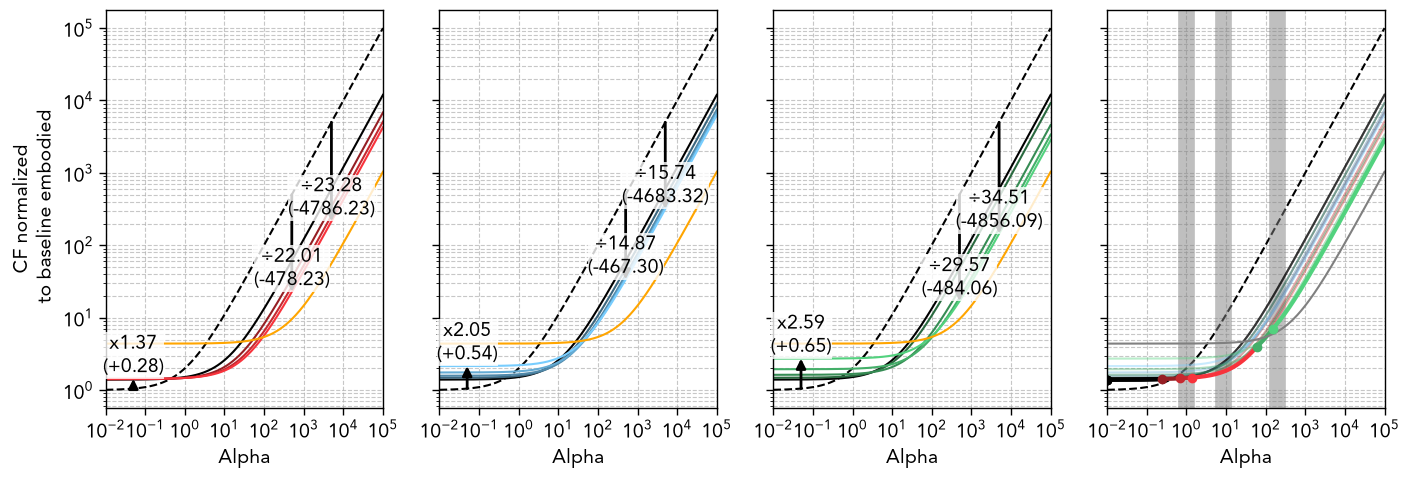

In [396]:
plot_theor = 1
plot_soa = 1
plot_our = 0
plot_soa_only_last_one =1
highlight_best = 1


# Plot the operation footprint vs FFT throughput
fig, ax = plt.subplots(1,4,figsize=(2*7.16, 5), sharey='row', squeeze=False)
####################################################################################################################################

for k in range(3):
    ax[0,k].grid(True, which='both', linestyle='--', alpha=0.7)
    ax[0,k].grid(True, which='both', linestyle='--', alpha=0.7)

    # Add our accelerator
    
    #for i, alp in enumerate(array_alpha):
    #    p = ax[0,k].axvline(alp,   color = 'gray' , linestyle ='-', linewidth=12, alpha= 0.5)

    p = ax[0,k].plot(alpha_studied,  1+alpha_studied,   color = 'black' , linestyle ='--', label = "Baseline system")

    for i in range(0,arch_Dim):
        for d, j in enumerate(analysis_Mem_type):
            p = ax[0,k].plot(alpha_studied,   theor_ncf_res[:,k,i,d,0],   color = color_array[k,i] , linestyle ='-', label = "Acc. level %i"%(i+1))

    
    for a, alpha_val in enumerate(alpha_to_study_array):
        for d, j in enumerate(analysis_Mem_type):
            index = np.argmin(np.abs(alpha_studied-alpha_val))
            ratio = (1+alpha_val)/theor_ncf_res[index,k,arch_Dim_array[k]-1,d,0]
            ax[0,k].annotate('', xy=(alpha_val, theor_ncf_res[index,k,arch_Dim_array[k]-1,d,0]), xytext=(alpha_val, 1+alpha_val),arrowprops=dict(arrowstyle='-|>', color='black', lw=2, shrinkA = 0, shrinkB = 0))
            if ratio>1:
                ax[0,k].text(alpha_val,  theor_ncf_res[index,k,arch_Dim_array[k]-1,d,0] , "÷%.2f\n(-%.2f)"%(ratio,(1-(1/ratio))*(1+alpha_val)), ha='center', va='bottom',  color="black",bbox=bbox_for_text)
            else:
                ax[0,k].text(alpha_val,  theor_ncf_res[index,k,arch_Dim_array[k]-1,d,0] , "x%.2f\n(+%.2f)"%(1/ratio,(1-ratio)*(1+alpha_val)), ha='center', va='bottom',  color="black",bbox=bbox_for_text)


    if plot_soa:
        if plot_soa_only_last_one : 
            p = ax[0,k].plot(alpha_studied,   soa_ncf_res[:,-1,0],   color = 'Orange', label = "S-o-A")
        else:
            for i in range(soa_area_ratio.shape[0]):
                p = ax[0,k].plot(alpha_studied,   soa_ncf_res[:,i,0], linestyle ='-.')

    if plot_our:
        for i in range(our_area_ratio.shape[0]):
            p = ax[0,k].plot(alpha_studied,   our_ncf_res[:,i,0],   color = listColor[i+6] , linestyle ='--', label = "Our")

    ax[0,k].set_xscale("log")
    ax[0,k].set_xlim([1e-2, np.max(alpha_studied)])
    ax[0,k].set_yscale("log")
    ax[0,k].set_xlabel("Alpha")
    ax[0,k].xaxis.set_major_locator(ticker.LogLocator(base=10.0, numticks=10))
####################################################################################################################################

curves = []
curve_colors = []

p = ax[0,-1].plot(alpha_studied,  1+alpha_studied,   color = 'black' , linestyle ='--')

if highlight_best:
    alpha = 0.4
else:
    alpha=1


for i, alp in enumerate(array_alpha):
    p = ax[0,-1].axvline(alp,   color = 'gray' , linestyle ='-', linewidth=12, alpha= 0.5)

if plot_theor:
    for k in range(3):

        # Add our accelerator
        for i in range(0,arch_Dim):
            for d, j in enumerate(analysis_Mem_type):
                p = ax[0,-1].plot(alpha_studied,   (theor_ncf_res[:,k,i,d,0]),   color = color_array[k,i] , linestyle ='-', alpha=alpha)
                curves.append(  theor_ncf_res[:,k,i,d,0])
                curve_colors.append(color_array[k,i])


    # Highlight, at each x, the curve with the highest value there
    if highlight_best:
        curves = np.array(curves)
        min_values = np.nanmin(curves, axis=0)
        for curve, color in zip(curves, curve_colors):
            highlight = np.where(curve == min_values, curve, np.nan)
            ax[0,-1].plot   (alpha_studied, highlight, color=color, linestyle='-', linewidth=3) # , marker = 'o',markersize=3 )
            index_first = (~np.isnan(highlight)).argmax()
            ax[0,-1].scatter(alpha_studied[index_first], highlight[index_first], color=color, marker='o',zorder=5) # , marker = 'o',markersize=3 , linewidth=6)
            


if plot_soa:
    if plot_soa_only_last_one : 
        p = ax[0,-1].plot(alpha_studied,   soa_ncf_res[:,-1,0],   color = 'gray', linestyle ='-')
    else:
        for i in range(soa_area_ratio.shape[0]):
            p = ax[0,-1].plot(alpha_studied,   soa_ncf_res[:,i,0],   color = listColor[np.mod(i,len(listColor))] , linestyle ='-.')

if plot_our:
    for i in range(our_area_ratio.shape[0]):
        p = ax[0,-1].plot(alpha_studied,   our_ncf_res[:,i,0],   color = listColor[i+6] , linestyle ='--')


ax[0,-1].set_xlabel('Alpha')
ax[0,-1].grid(True, which='both', linestyle='--', alpha=0.7)
ax[0,-1].set_xscale("log")
ax[0,-1].set_yscale("log")
ax[0,-1].set_xlim([1e-2, np.max(alpha_studied)])
ax[0,-1].set_xlabel("Alpha")
ax[0,-1].xaxis.set_major_locator(ticker.LogLocator(base=10.0, numticks=10))


ax[0, 0].set_ylabel("CF normalized\n to baseline embodied")

fig.tight_layout()
plt.savefig("NCF.svg")
# Add legend
plt.show()


C:\Users\maistriauxp\AppData\Local\Temp\ipykernel_33104\1558987158.py:72: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[0,0].legend()


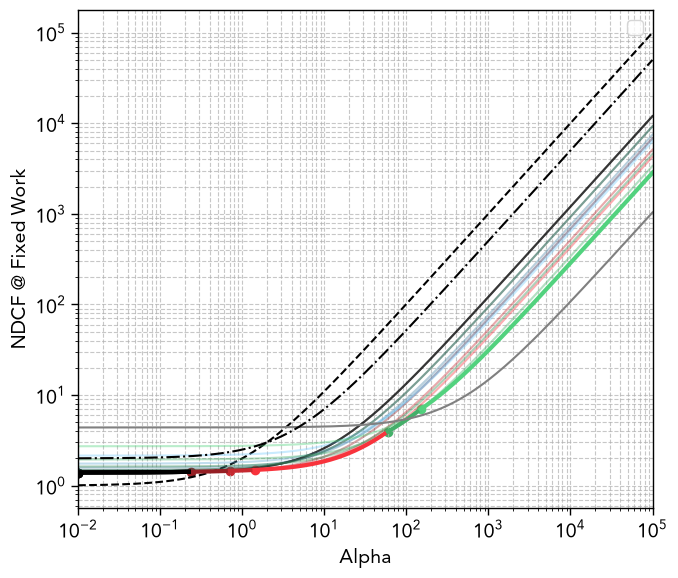

In [397]:
plot_theor = 1
plot_cm0   = 1
plot_soa = 1
plot_our = 0
plot_soa_only_last_one =1
highlight_best = 1

# Plot the operation footprint vs FFT throughput
fig, ax = plt.subplots(1,1,figsize=(7, 6), sharey='row', squeeze=False)

curves = []
curve_colors = []

p = ax[0,0].plot(alpha_studied,  1+alpha_studied,   color = 'black' , linestyle ='--')

if highlight_best:
    alpha = 0.4
else:
    alpha=1


if plot_theor:
    for k in range(3):

        # Add our accelerator

        for i in range(0,arch_Dim):
            for d, j in enumerate(analysis_Mem_type):
                p = ax[0,0].plot(alpha_studied,   (theor_ncf_res[:,k,i,d,0]),   color = color_array[k,i] , linestyle ='-', alpha=alpha)
                curves.append(  theor_ncf_res[:,k,i,d,0])
                curve_colors.append(color_array[k,i])


    # Highlight, at each x, the curve with the highest value there
    if highlight_best:
        curves = np.array(curves)
        min_values = np.nanmin(curves, axis=0)
        for curve, color in zip(curves, curve_colors):
            highlight = np.where(curve == min_values, curve, np.nan)
            ax[0,0].plot   (alpha_studied, highlight, color=color, linestyle='-', linewidth=3) # , marker = 'o',markersize=3 )
            index_first = (~np.isnan(highlight)).argmax()
            ax[0,0].scatter(alpha_studied[index_first], highlight[index_first], color=color, marker='o') # , marker = 'o',markersize=3 , linewidth=6)
            


if plot_soa:
    if plot_soa_only_last_one : 
        p = ax[0,0].plot(alpha_studied,   soa_ncf_res[:,-1,0],   color = 'gray', linestyle ='-')
    else:
        for i in range(soa_area_ratio.shape[0]):
            p = ax[0,0].plot(alpha_studied,   soa_ncf_res[:,i,0],   color = listColor[i] , linestyle ='-.')

if plot_our:
    for i in range(our_area_ratio.shape[0]):
        p = ax[0,0].plot(alpha_studied,   our_ncf_res[:,i,0],   color = listColor[i+6] , linestyle ='--')

if plot_cm0: 
    p = ax[0,0].plot(alpha_studied,   cm0_ncf_res[:,0],   color = 'Black' , linestyle ='-.')


ax[0,0].set_xlabel('ALpha')
ax[0,0].grid(True, which='both', linestyle='--', alpha=0.7)
#ax[0,0].hlines(y=1,xmin = 0, xmax=1, color= "black")
ax[0,0].set_xscale("log")
#ax[0,0].set_yscale("log")
ax[0,0].set_yscale("log")
ax[0,0].set_xlim([1e-2, np.max(alpha_studied)])
ax[0,0].set_xlabel("Alpha")


ax[0,0].set_ylabel("NDCF @ Fixed Work")
ax[0,0].legend()

# Add legend
fig.tight_layout()
plt.show()



In [333]:


for i, alpha_val in enumerate(alpha_to_study_array):
    print(f"-------- Alpha = {alpha_val:.2e}  -------- ") 
    index = np.argmin(np.abs(alpha_studied-alpha_val))
    #index = np.clip(int(alpha_n*(np.log10(alpha_val)-alpha_s_low)/(alpha_s_high-alpha_s_low)),a_max= len(alpha_studied)-1, a_min=None)
    for k in range(3):
        for i in range(arch_Dim):
            for d, j in enumerate(analysis_Mem_type):
                ratio = (1+alpha_val)/theor_ncf_res[index,k,i,d,0]
                if ratio>1:
                    print(f"THEOR {k}{j},{i}:  ncf_ratio_baseline=/{ratio:.2e}")
                else:
                    print(f"THEOR {k}{j},{i}:  ncf_ratio_baseline=x{1/ratio:.2e}")
            

-------- Alpha = 5.00e-02  -------- 
THEOR 01,0:  ncf_ratio_baseline=x1.33e+00
THEOR 01,1:  ncf_ratio_baseline=x1.34e+00
THEOR 01,2:  ncf_ratio_baseline=x1.35e+00
THEOR 01,3:  ncf_ratio_baseline=x1.36e+00
THEOR 01,4:  ncf_ratio_baseline=xnan
THEOR 11,0:  ncf_ratio_baseline=x1.33e+00
THEOR 11,1:  ncf_ratio_baseline=x1.41e+00
THEOR 11,2:  ncf_ratio_baseline=x1.50e+00
THEOR 11,3:  ncf_ratio_baseline=x1.67e+00
THEOR 11,4:  ncf_ratio_baseline=x2.04e+00
THEOR 21,0:  ncf_ratio_baseline=x1.33e+00
THEOR 21,1:  ncf_ratio_baseline=x1.41e+00
THEOR 21,2:  ncf_ratio_baseline=x1.55e+00
THEOR 21,3:  ncf_ratio_baseline=x1.85e+00
THEOR 21,4:  ncf_ratio_baseline=x2.59e+00
-------- Alpha = 5.00e+02  -------- 
THEOR 01,0:  ncf_ratio_baseline=/3.06e+01
THEOR 01,1:  ncf_ratio_baseline=/5.03e+01
THEOR 01,2:  ncf_ratio_baseline=/6.40e+01
THEOR 01,3:  ncf_ratio_baseline=/7.41e+01
THEOR 01,4:  ncf_ratio_baseline=xnan
THEOR 11,0:  ncf_ratio_baseline=/3.06e+01
THEOR 11,1:  ncf_ratio_baseline=/3.84e+01
THEOR 11,2: 

In [334]:

alpha_s_low_bar     = np.clip(  -1        ,a_max= alpha_s_high, a_min=alpha_s_low)
alpha_s_high_bar    = np.clip(   3        ,a_max= alpha_s_high, a_min=alpha_s_low)

index_low   = np.clip(int(alpha_n*(alpha_s_low_bar -alpha_s_low)/(alpha_s_high-alpha_s_low)) ,a_max= len(alpha_studied), a_min=0)
index_high  = np.clip(int(alpha_n*(alpha_s_high_bar-alpha_s_low)/(alpha_s_high-alpha_s_low)) ,a_max= len(alpha_studied), a_min=0)


alpha_studied_bar = alpha_studied[index_low:index_high+1]
alpha_n_bar = len(alpha_studied_bar)


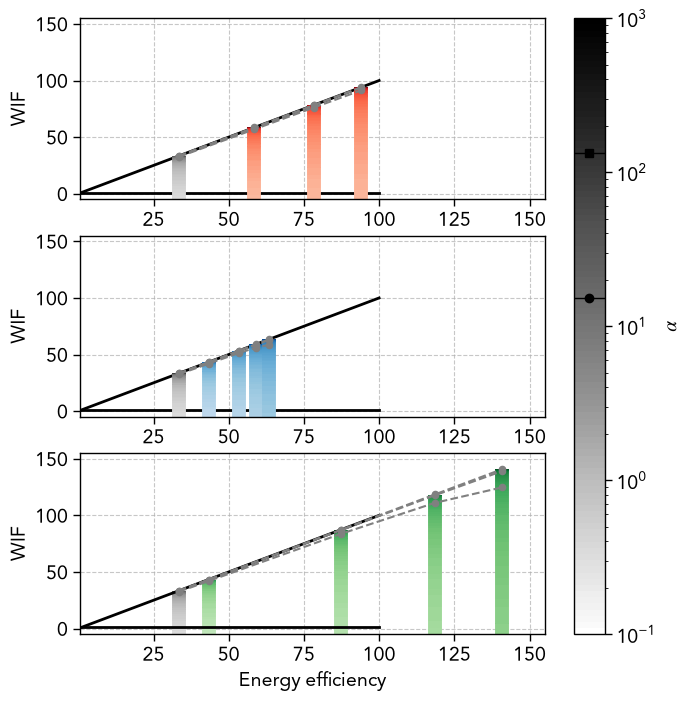

In [335]:
plt_soa = False
# -----------------

# ASI Framework separations
metric_space = np.linspace(0.5, 100, 100)


sep_strongly_sustainable = 1/metric_space
sep_weakly_sustainable   = 1/metric_space

sep_strongly_sustainable[np.where(sep_strongly_sustainable<1)] =1
sep_weakly_sustainable  [np.where(sep_weakly_sustainable>1)]   =1

arch_color_map = ['Reds', 'Blues', 'Greens']

alphaViolin=0.5
widthViolin=0.2
bwViolin   =0.01
# Plot the operation footprint vs FFT throughput

fig, ax = plt.subplots(3,1,figsize=(7.5*1, 8), squeeze=False)

metric =  (1/theor_energy_ratio[:,:arch_Dim,:]) 

metric_sust = theor_ncf_test[:,:,:arch_Dim,:] 



marker_list = ['o','s','^','X','h','p','*','<','+']

ax[-1,0].set_xlabel('Energy efficiency')

norm = matplotlib.colors.LogNorm(vmin=alpha_studied_bar.min(), vmax=alpha_studied_bar.max())

start_cmap = 0
stop_cmap  = 1
cmap_points = (np.linspace(start_cmap, stop_cmap, 100))**(0.7)

for k in range(3):
    ax[k,0].set_xscale('linear')
    ax[k,0].set_yscale('linear')
    ax[k,0].set_ylabel('WIF')
    ax[k,0].plot(metric_space, metric_space, 'black', linewidth=2, label='Strongly Sustainable')
    ax[k,0].plot(metric_space, np.ones(len(metric_space)), 'black', linewidth=2, label='Strongly Sustainable')
    try:
        #ax[k,0].set_xlim([0.5,1.1*np.nanmax(metric[:,:,analysis_Mem_type])])
        ax[k,0].set_xlim([0.5,1.1*np.nanmax(metric[:,:,analysis_Mem_type])])
    except:
        print("Limit Error")
    ax[k,0].set_ylim([-5 ,1.1*np.nanmax(metric_sust) ])#1.1*np.max(metric_sust)])
    ax[k,0].grid(True, which='both', linestyle='--', alpha=0.7)

 
    for d, j in enumerate(analysis_Mem_type):

        k = 2-k
        for i in range(0,arch_Dim):  

            points = np.array([metric[k,i,j]*np.ones((len(alpha_studied_bar))),metric_sust[index_low:index_high+1,k,i,d]]).T.reshape(-1, 1, 2)
            segments = np.concatenate([points[:-1], points[1:]],axis=1)
            segments[:,1,1] = segments[:,1,1]+0.05
            if i == 0 : 
                lc = LineCollection(segments, cmap=ListedColormap(mpl.colormaps["Grays"](cmap_points))    ,norm=norm           ) 
            else:
                lc = LineCollection(segments, cmap=ListedColormap(mpl.colormaps[arch_color_map[k]](cmap_points))  ,norm=norm               ) 
            lc.set_array(alpha_studied_bar)
            lc.set_linewidth(10)
            ax[k,0].add_collection(lc)

    if plt_soa:
        points = np.array([1/soa_energy_ratio[-1]*np.ones((len(alpha_studied_bar))),soa_ncf_test[index_low:index_high+1,-1]]).T.reshape(-1, 1, 2)
        segments = np.concatenate([points[:-1], points[1:]],axis=1)
        segments[:,1,1] = segments[:,1,1]+0.05
        lc = LineCollection(segments, cmap=ListedColormap(mpl.colormaps["Oranges"](cmap_points))  ,norm=norm               ) 
        lc.set_array(alpha_studied_bar)
        lc.set_linewidth(10)
        ax[k,0].add_collection(lc)


hline_w = 0.7#np.nanmax(metric)/30
for k in range(3):
    for d, j in enumerate(analysis_Mem_type):
        k = 2-k

        alpha_inv = np.log10(array_alpha) #np.arange(start=alpha_s_low_bar, stop=alpha_s_high_bar)
        for i_alp,alp in enumerate(alpha_inv):
            index = np.clip(int(alpha_n*(alp-alpha_s_low)/(alpha_s_high-alpha_s_low)),a_max= len(alpha_studied)-1, a_min=None)
            for i in range(0,arch_Dim):  
                #ax[k,0].hlines (               metric_sust[index,k,i,d], xmin = metric[k,i,j]-hline_w, xmax=metric[k,i,j]+hline_w, linewidth=0.7, color='black', alpha=0.6,zorder=5)
                #ax[k,0].scatter(metric[k,i,j], metric_sust[index,k,i,d], marker = marker_list [i_alp], color='black',zorder=5)
                ax[k,0].scatter(metric[k,i,j], metric_sust[index,k,i,d], marker = "o" , color='gray',zorder=5, s=20)

            ax[k,0].plot (metric[k,:arch_Dim_array[k],j], metric_sust[index,k,:arch_Dim_array[k],d], color='gray', linestyle ='--', alpha=1)

if plt_soa:
    for k in range(3):
        alpha_inv = np.log10(array_alpha) #np.arange(start=alpha_s_low_bar, stop=alpha_s_high_bar)
        for i_alp,alp in enumerate(alpha_inv):
            index = np.clip(int(alpha_n*(alp-alpha_s_low)/(alpha_s_high-alpha_s_low)),a_max= len(alpha_studied)-1, a_min=None)
            ax[k,0].scatter(1/soa_energy_ratio[-1], soa_ncf_test[index,-1], marker = marker_list [i_alp], color='black',zorder=5)

cbar = fig.colorbar(matplotlib.cm.ScalarMappable(cmap=ListedColormap(mpl.colormaps['Grays'](cmap_points)),norm=norm),ax=ax,orientation='vertical',label='Alpha')
cbar.set_label(r'$\alpha$')
for i_alp,alp in enumerate(np.log10(array_alpha)): #np.arange(start=alpha_s_low_bar, stop=alpha_s_high_bar,step =1.00 )):
    cbar.ax.hlines(10**alp,xmin = -0.4, xmax=1, linewidth=1, color='black', alpha=1)
    cbar.ax.plot(0.5, 10**alp, marker = marker_list [i_alp], color='black')


plt.savefig("WIF.svg", bbox_inches="tight")
# Add legend
plt.show()

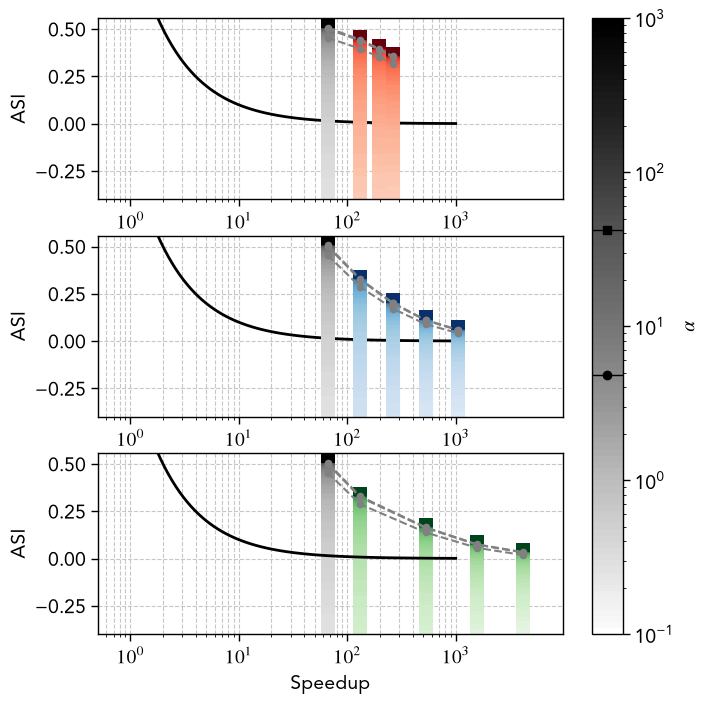

In [302]:
plot_soa=False
# -----------------


sep_strongly_sustainable[np.where(sep_strongly_sustainable<1)] =1
sep_weakly_sustainable  [np.where(sep_weakly_sustainable>1)]   =1

arch_color_map = ['Reds', 'Blues', 'Greens']

alphaViolin=0.5
widthViolin=0.2
bwViolin   =0.01
# Plot the operation footprint vs FFT throughput

fig, ax = plt.subplots(3,1,figsize=(7.5*1, 8), squeeze=False)

metric =  np.log10(theor_speedup_ratio[:,:arch_Dim,:])
metric_sust = (theor_asi_res[:,:,:arch_Dim,:]) 


marker_list = ['o','s','^','X','h','p','*','<','+']

s_log_min = -0.5
s_log_max = 3
metric_space = np.linspace(s_log_min, s_log_max, 100)

log_ticks = np.array([])
for i  in np.arange(np.floor(s_log_min), np.ceil(s_log_max),1) :
    log_ticks = np.append(log_ticks,i + np.log10(np.linspace(1,10, 10)))

formatter = FuncFormatter(lambda x_val, tick_pos: "$10^{{{:.0f}}}$".format(x_val))

norm = matplotlib.colors.LogNorm(vmin=alpha_studied_bar.min(), vmax=alpha_studied_bar.max())

start_cmap = 0
stop_cmap  = 1
cmap_points = (np.linspace(start_cmap, stop_cmap, 100))**(0.7)

for k in range(3):
    ax[k,0].set_xscale('linear')
    ax[k,0].set_yscale('linear')
    ax[k,0].set_ylabel('ASI')
    ax[k,0].plot(metric_space, 1/(10**metric_space), 'black', linewidth=2, label='Strongly Sustainable')
    ax[k,0].plot(metric_space, np.ones(len(metric_space)), 'black', linewidth=2, label='Strongly Sustainable')
    ax[k,0].set_xlabel('Speedup')
    ax[k,0].set_xlim([-0.3,1.1*np.nanmax(metric[:,:,analysis_Mem_type])])
    try :
        ax[k,0].set_ylim([-0.4 ,1.1*np.nanmax(metric_sust) ])#1.1*np.max(metric_sust)])
    except:
        print("Limit issue")
        ax[k,0].set_ylim([-1.5 ,1.3 ])#1.1*np.max(metric_sust)])
    ax[k,0].grid(True, which='both', linestyle='--', alpha=0.7)
    ax[k,0].xaxis.set_major_locator(ticker.MultipleLocator(1))
    ax[k,0].xaxis.set_major_formatter(formatter)
    ax[k,0].xaxis.set_minor_locator(ticker.FixedLocator(log_ticks))

 
    for d, j in enumerate(analysis_Mem_type):

        k = 2-k
        for i in range(0,arch_Dim):  

            points = np.array([metric[k,i,j]*np.ones((len(alpha_studied_bar))),metric_sust[index_low:index_high+1,k,i,d]]).T.reshape(-1, 1, 2)
            segments = np.concatenate([points[:-1], points[1:]],axis=1)
            segments[:,1,1] = segments[:,1,1]+0.05
            if i == 0 : 
                lc = LineCollection(segments, cmap=ListedColormap(mpl.colormaps["Grays"](cmap_points))    ,norm=norm           ) #cmap = ListedColormap(mpl.colormaps["Grays"](np.linspace(0.2, 1, 100))))
            else:
                lc = LineCollection(segments, cmap=ListedColormap(mpl.colormaps[arch_color_map[k]](cmap_points))  ,norm=norm               ) #cmap = ListedColormap(mpl.colormaps[arch_color_map[k]](np.linspace(0.2, 1, 100))))
            lc.set_array(alpha_studied_bar)
            lc.set_linewidth(10)
            ax[k,0].add_collection(lc)


    if plot_soa:
        points = np.array([1.05*np.log10(soa_speedup_ratio[-1])*np.ones((len(alpha_studied_bar))),soa_asi_res[index_low:index_high+1,-1]]).T.reshape(-1, 1, 2)
        segments = np.concatenate([points[:-1], points[1:]],axis=1)
        segments[:,1,1] = segments[:,1,1]+0.05
        lc = LineCollection(segments, cmap=ListedColormap(mpl.colormaps["Oranges"](cmap_points))  ,norm=norm               ) #cmap = ListedColormap(mpl.colormaps[arch_color_map[k]](np.linspace(0.2, 1, 100))))
        lc.set_array(alpha_studied_bar)
        lc.set_linewidth(10)
        ax[k,0].add_collection(lc)

hline_w = np.nanmax(metric)/40
for k in range(3):
    for d, j in enumerate(analysis_Mem_type):
        k = 2-k

        alpha_inv = np.log10(array_alpha) #np.arange(start=alpha_s_low_bar, stop=alpha_s_high_bar)
        for i_alp,alp in enumerate(alpha_inv):
            index = np.clip(int(alpha_n*(alp-alpha_s_low)/(alpha_s_high-alpha_s_low)),a_max= len(alpha_studied)-1, a_min=None)
            for i in range(0,arch_Dim):  
                #ax[k,0].hlines (               metric_sust[index,k,i,d], xmin = metric[k,i,j]-hline_w, xmax=metric[k,i,j]+hline_w, linewidth=0.7, color='black', alpha=0.6,zorder=5)
                #ax[k,0].scatter(metric[k,i,j], metric_sust[index,k,i,d], marker = marker_list [i_alp], color='black',zorder=5)
                ax[k,0].scatter(metric[k,i,j], metric_sust[index,k,i,d], marker = "o" , color='gray',zorder=5, s=20)

            ax[k,0].plot (metric[k,:arch_Dim_array[k],j], metric_sust[index,k,:arch_Dim_array[k],d], color='gray', linestyle ='--', alpha=1)

if plot_soa:
    for k in range(3):
        alpha_inv = np.log10(array_alpha) #np.arange(start=alpha_s_low_bar, stop=alpha_s_high_bar)
        for i_alp,alp in enumerate(alpha_inv):
            index = np.clip(int(alpha_n*(alp-alpha_s_low)/(alpha_s_high-alpha_s_low)),a_max= len(alpha_studied)-1, a_min=None)
            ax[k,0].scatter(1.05*np.log10(soa_speedup_ratio[-1]), soa_asi_res[index,-1], marker = marker_list [i_alp], color='black',zorder=5)

    
cbar = fig.colorbar(matplotlib.cm.ScalarMappable(cmap=ListedColormap(mpl.colormaps['Grays'](cmap_points)),norm=norm),ax=ax,orientation='vertical',label='Alpha')
cbar.set_label(r'$\alpha$')
for i_alp,alp in enumerate(np.log10(array_alpha)): #np.arange(start=alpha_s_low_bar, stop=alpha_s_high_bar+1,step =1.00 )):
    cbar.ax.hlines(10**alp,xmin = -0.4, xmax=1, linewidth=1, color='black', alpha=1)
    cbar.ax.plot(0.5, 10**alp, marker = marker_list [i_alp], color='black')

plt.savefig("ASI.svg", bbox_inches="tight")
# Add legend
plt.show()


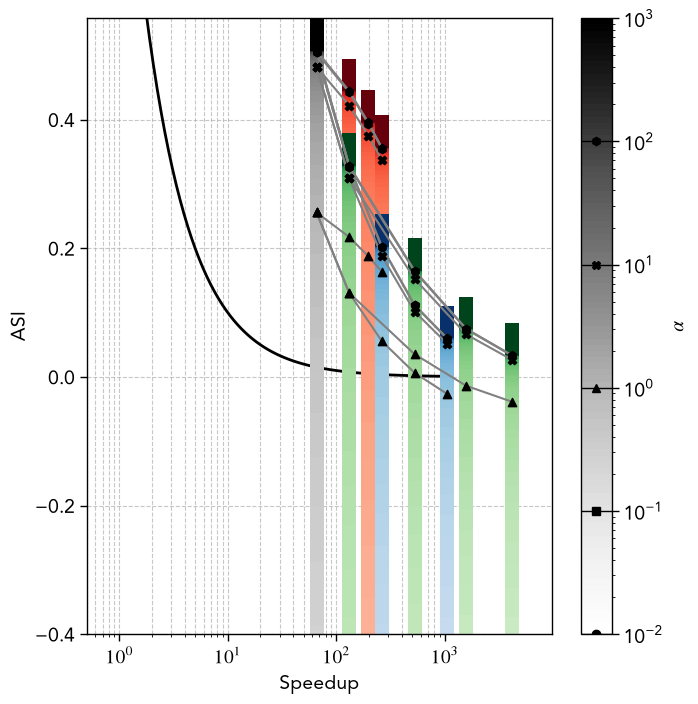

In [303]:

# -----------------


sep_strongly_sustainable[np.where(sep_strongly_sustainable<1)] =1
sep_weakly_sustainable  [np.where(sep_weakly_sustainable>1)]   =1

arch_color_map = ['Reds', 'Blues', 'Greens']

alphaViolin=0.5
widthViolin=0.2
bwViolin   =0.01
# Plot the operation footprint vs FFT throughput

fig, ax = plt.subplots(1,1,figsize=(7.5*1, 8), squeeze=False)

metric =  np.log10(theor_speedup_ratio[:,:arch_Dim,:])
metric_sust = (theor_asi_res[:,:,:arch_Dim,:]) 

arch_color_map = ['Reds', 'Blues', 'Greens']

marker_list = ['o','s','^','X','h','p','*','<','+']

s_log_min = -0.5
s_log_max = 3
metric_space = np.linspace(s_log_min, s_log_max, 100)

log_ticks = np.array([])
for i  in np.arange(np.floor(s_log_min), np.ceil(s_log_max),1) :
    log_ticks = np.append(log_ticks,i + np.log10(np.linspace(1,10, 10)))

formatter = FuncFormatter(lambda x_val, tick_pos: "$10^{{{:.0f}}}$".format(x_val))


cmap = colormaps['Grays']
norm = matplotlib.colors.LogNorm(vmin=alpha_studied.min(), vmax=alpha_studied.max())

ax[0,0].set_xscale('linear')
ax[0,0].set_yscale('linear')
ax[0,0].set_ylabel('ASI')
ax[0,0].plot(metric_space, 1/(10**metric_space), 'black', linewidth=2, label='Strongly Sustainable')
ax[0,0].plot(metric_space, np.ones(len(metric_space)), 'black', linewidth=2, label='Strongly Sustainable')
ax[0,0].set_xlabel('Speedup')
ax[0,0].set_xlim([-0.3,1.1*np.nanmax(metric[:,:,analysis_Mem_type])])
try :
    ax[0,0].set_ylim([-0.4 ,1.1*np.nanmax(metric_sust) ])#1.1*np.max(metric_sust)])
except:
    print("Limit issue")
    ax[0,0].set_ylim([-1.5 ,1.3 ])#1.1*np.max(metric_sust)])
ax[0,0].grid(True, which='both', linestyle='--', alpha=0.7)
ax[0,0].xaxis.set_major_locator(ticker.MultipleLocator(1))
ax[0,0].xaxis.set_major_formatter(formatter)
ax[0,0].xaxis.set_minor_locator(ticker.FixedLocator(log_ticks))

for k in range(3):
    for d, j in enumerate(analysis_Mem_type):

        for i in range(0,arch_Dim):  

            points = np.array([metric[k,i,j]*np.ones((len(alpha_studied))),metric_sust[:,k,i,d]]).T.reshape(-1, 1, 2)
            segments = np.concatenate([points[:-1], points[1:]],axis=1)
            segments[:,1,1] = segments[:,1,1]+0.05
            if i == 0 : 
                lc = LineCollection(segments, cmap=ListedColormap(mpl.colormaps["Grays"](np.linspace(0.0, 1, 100)))    ,norm=norm           ) #cmap = ListedColormap(mpl.colormaps["Grays"](np.linspace(0.2, 1, 100))))
            else:
                lc = LineCollection(segments, cmap=ListedColormap(mpl.colormaps[arch_color_map[k]](np.linspace(0.0, 1, 100)))  ,norm=norm               ) #cmap = ListedColormap(mpl.colormaps[arch_color_map[k]](np.linspace(0.2, 1, 100))))
            lc.set_array(alpha_studied)
            lc.set_linewidth(10)
            ax[0,0].add_collection(lc)

hline_w = np.nanmax(metric)/40
for k in range(3):
    for d, j in enumerate(analysis_Mem_type):

        alpha_inv = np.arange(start=alpha_s_low, stop=alpha_s_high+1)
        for i_alp,alp in enumerate(alpha_inv):
            index = np.clip(int(alpha_n*(alp-alpha_s_low)/(alpha_s_high-alpha_s_low)),a_max= len(alpha_studied)-1, a_min=None)
            for i in range(0,arch_Dim):  
                #ax[k,0].hlines (               metric_sust[index,k,i,d], xmin = metric[k,i,j]-hline_w, xmax=metric[k,i,j]+hline_w, linewidth=0.7, color='black', alpha=0.6,zorder=5)
                ax[0,0].scatter(metric[k,i,j], metric_sust[index,k,i,d], marker = marker_list [i_alp], color='black',zorder=5)

            ax[0,0].plot (metric[k,:arch_Dim_array[k],j], metric_sust[index,k,:arch_Dim_array[k],d], color='gray', linestyle ='-', alpha=1)

    
cbar = fig.colorbar(matplotlib.cm.ScalarMappable(cmap=ListedColormap(mpl.colormaps['Grays'](np.linspace(0.0, 1, 100))),norm=norm),ax=ax,orientation='vertical',label='Alpha')
cbar.set_label(r'$\alpha$')
for i_alp,alp in enumerate(np.arange(start=alpha_s_low, stop=alpha_s_high+1,step =1.00 )):
    index = np.clip(int(alpha_n*(alp-alpha_s_low)/(alpha_s_high-alpha_s_low)),a_max= len(alpha_studied)-1, a_min=None)
    cbar.ax.hlines(10**alp,xmin = -0.4, xmax=1, linewidth=1, color='black', alpha=1)
    cbar.ax.plot(0.5, 10**alp, marker = marker_list [i_alp], color='black')

plt.savefig("ASI.svg", bbox_inches="tight")
# Add legend
plt.show()


C:\Users\maistriauxp\AppData\Local\Temp\ipykernel_33104\2826800407.py:48: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  ax[k,0].set_ylim([-5 ,1.1*np.nanmax(metric_sust) ])#1.1*np.max(metric_sust)])


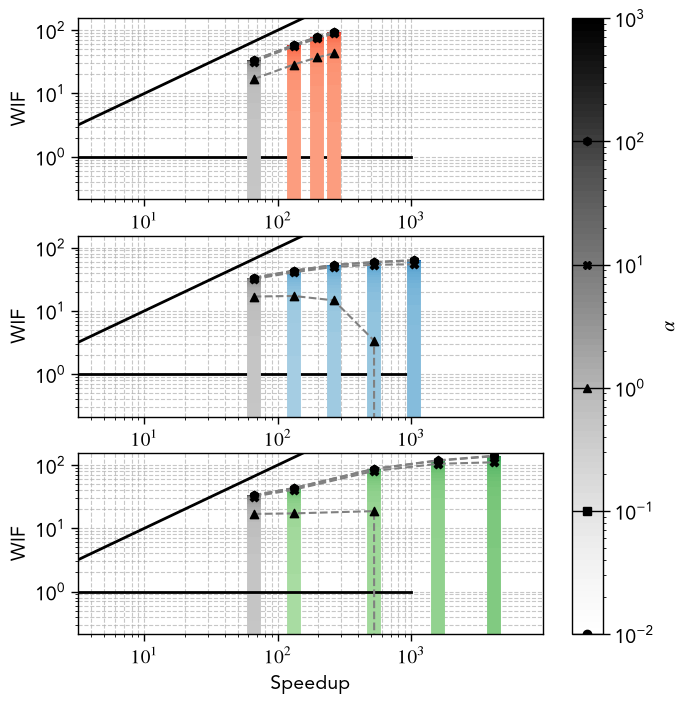

In [304]:

# -----------------


sep_strongly_sustainable[np.where(sep_strongly_sustainable<1)] =1
sep_weakly_sustainable  [np.where(sep_weakly_sustainable>1)]   =1

arch_color_map = ['Reds', 'Blues', 'Greens']

alphaViolin=0.5
widthViolin=0.2
bwViolin   =0.01
# Plot the operation footprint vs FFT throughput

fig, ax = plt.subplots(3,1,figsize=(7.5*1, 8), squeeze=False)

metric =  np.log10(theor_speedup_ratio[:,:arch_Dim,:])
metric_sust = theor_ncf_test[:,:,:arch_Dim,:] 

arch_color_map = ['Reds', 'Blues', 'Greens']

marker_list = ['o','s','^','X','h','p','*','<','+']

s_log_min = -0.5
s_log_max = 3
metric_space = np.linspace(s_log_min, s_log_max, 100)

log_ticks = np.array([])
for i  in np.arange(np.floor(s_log_min), np.ceil(s_log_max),1) :
    log_ticks = np.append(log_ticks,i + np.log10(np.linspace(1,10, 10)))

formatter = FuncFormatter(lambda x_val, tick_pos: "$10^{{{:.0f}}}$".format(x_val))


cmap = colormaps['Grays']
norm = matplotlib.colors.LogNorm(vmin=alpha_studied.min(), vmax=alpha_studied.max())

for k in range(3):

    ax[k,0].set_xscale('linear')
    ax[k,0].set_yscale('log')
    ax[k,0].set_ylabel('WIF')
    ax[k,0].plot(metric_space, 10**metric_space, 'black', linewidth=2, label='Strongly Sustainable')
    ax[k,0].plot(metric_space, np.ones(len(metric_space)), 'black', linewidth=2, label='Strongly Sustainable')
    try:
        ax[k,0].set_xlim([0.5,1.1*np.nanmax(metric[:,:,analysis_Mem_type])])
    except:
        print("Limit Error")
    ax[k,0].set_ylim([-5 ,1.1*np.nanmax(metric_sust) ])#1.1*np.max(metric_sust)])
    ax[k,0].grid(True, which='both', linestyle='--', alpha=0.7)

    ax[k,0].xaxis.set_major_locator(ticker.MultipleLocator(1))
    ax[k,0].xaxis.set_major_formatter(formatter)
    ax[k,0].xaxis.set_minor_locator(ticker.FixedLocator(log_ticks))

 
    for d, j in enumerate(analysis_Mem_type):

        k = 2-k
        for i in range(0,arch_Dim):  

            points = np.array([metric[k,i,j]*np.ones((len(alpha_studied))),metric_sust[:,k,i,d]]).T.reshape(-1, 1, 2)
            segments = np.concatenate([points[:-1], points[1:]],axis=1)
            segments[:,1,1] = segments[:,1,1]+0.05
            if i == 0 : 
                lc = LineCollection(segments, cmap=ListedColormap(mpl.colormaps["Grays"](np.linspace(0.0, 1, 100)))    ,norm=norm           ) #cmap = ListedColormap(mpl.colormaps["Grays"](np.linspace(0.2, 1, 100))))
            else:
                lc = LineCollection(segments, cmap=ListedColormap(mpl.colormaps[arch_color_map[k]](np.linspace(0.0, 1, 100)))  ,norm=norm               ) #cmap = ListedColormap(mpl.colormaps[arch_color_map[k]](np.linspace(0.2, 1, 100))))
            lc.set_array(alpha_studied)
            lc.set_linewidth(10)
            ax[k,0].add_collection(lc)


hline_w = np.nanmax(metric)/30
for k in range(3):
    for d, j in enumerate(analysis_Mem_type):
        k = 2-k

        alpha_inv = np.arange(start=alpha_s_low, stop=alpha_s_high+1)
        for i_alp,alp in enumerate(alpha_inv):
            index = np.clip(int(alpha_n*(alp-alpha_s_low)/(alpha_s_high-alpha_s_low)),a_max= len(alpha_studied)-1, a_min=None)
            for i in range(0,arch_Dim):  
                #ax[k,0].hlines (               metric_sust[index,k,i,d], xmin = metric[k,i,j]-hline_w, xmax=metric[k,i,j]+hline_w, linewidth=0.7, color='black', alpha=0.6,zorder=5)
                ax[k,0].scatter(metric[k,i,j], metric_sust[index,k,i,d], marker = marker_list [i_alp], color='black',zorder=5)

            ax[k,0].plot (metric[k,:arch_Dim_array[k],j], metric_sust[index,k,:arch_Dim_array[k],d], color='gray', linestyle ='--', alpha=1)
    

cbar = fig.colorbar(matplotlib.cm.ScalarMappable(cmap=ListedColormap(mpl.colormaps['Grays'](np.linspace(0.0, 1, 100))),norm=norm),ax=ax,orientation='vertical',label='Alpha')
cbar.set_label(r'$\alpha$')
for i_alp,alp in enumerate(np.arange(start=alpha_s_low, stop=alpha_s_high,step =1.00 )):
    index = int(alpha_n*(alp-alpha_s_low)/(alpha_s_high-alpha_s_low))
    cbar.ax.hlines(10**alp,xmin = -0.4, xmax=1, linewidth=1, color='black', alpha=1)
    cbar.ax.plot(0.5, 10**alp, marker = marker_list [i_alp], color='black')

ax[-1,0].set_xlabel('Speedup')
# Add legend
plt.show()
